# Koeltekaart Amsterdam — coverage analysis

**Question:** where in Amsterdam are people underserved by cooling places during heat?

**Inputs** (frozen snapshot in `data/raw/` — read-only, never write there):
- `locations.csv` — cooling places. Coordinates deliberately stripped; we reproduce them below.
- `buurten.geojson` — neighbourhood polygons with population.

**Outputs:** `data/processed/` — derived, disposable, safe to delete and regenerate.


In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd

RAW = Path("data/raw")
PROCESSED = Path("data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)
WGS84 = "EPSG:4326"   # degrees — what the CSV holds and what web maps want
RD = "EPSG:28992"     # Rijksdriehoek, metres — use for any distance or area

## 1. Load the locations

Read the CSV, then look before you leap: shape, columns, dtypes, missing addresses.


In [2]:
# your turn

df = pd.read_csv(RAW / "locations.csv").dropna(how="all")
buurten = gpd.read_file(RAW / "buurten.geojson")
print(buurten.crs)
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.describe())

EPSG:4326
(80, 25)
Index(['name', 'type', 'address', 'active', 'website_url', 'photo_url',
       'description', 'note', 'seating', 'toilets', 'free_water',
       'food_to_buy', 'own_food_ok', 'airco', 'wheelchair_accessible', 'games',
       'pets_ok', 'wifi', 'heat_mon', 'heat_tue', 'heat_wed', 'heat_thu',
       'heat_fri', 'heat_sat', 'heat_sun'],
      dtype='str')
name                     str
type                     str
address                  str
active                   str
website_url              str
photo_url                str
description              str
note                     str
seating                  str
toilets                  str
free_water               str
food_to_buy              str
own_food_ok              str
airco                    str
wheelchair_accessible    str
games                    str
pets_ok                  str
wifi                     str
heat_mon                 str
heat_tue                 str
heat_wed                 str
heat_thu         

## 2. Geocode the addresses

PDOK Locatieserver, one request per address. Cache the result into `data/processed/`
so a kernel restart doesn't re-hit the API 80 times.


In [3]:
import re

import requests

PDOK = "https://api.pdok.nl/bzk/locatieserver/search/v3_1/free"
session = requests.Session()  # reuse one TCP/TLS connection across ~80 calls


def geocode(address):
    """Return (lon, lat) for a Dutch address via PDOK, or (None, None)."""
    if not isinstance(address, str) or not address.strip():
        return None, None  # blank CSV cells arrive as float('nan'), not str

    try:
        r = session.get(
            PDOK,
            params={"q": address, "rows": 1, "fq": "type:adres"},
            timeout=10,
        )
        r.raise_for_status()
        docs = r.json()["response"]["docs"]
    except Exception:
        return None, None  # one bad row must not abort the whole batch

    if not docs:
        return None, None

    # centroide_ll is WKT: "POINT(4.8926 52.3730)" — x then y, lon then lat
    m = re.match(r"POINT\(([-\d.]+) ([-\d.]+)\)", docs[0]["centroide_ll"])
    return (float(m.group(1)), float(m.group(2))) if m else (None, None)


CACHE = PROCESSED / "geocoded.csv"

if CACHE.exists():
    geo = pd.read_csv(CACHE)
else:
    coords = df["address"].apply(geocode)  # Series of (lon, lat) tuples
    geo = df.assign(longitude=coords.str[0], latitude=coords.str[1])
    geo.to_csv(CACHE, index=False)

print(f"{geo['latitude'].isna().sum()} of {len(geo)} rows without coordinates")
geo[["name", "address", "longitude", "latitude"]].head()


0 of 80 rows without coordinates


,name,address,longitude,latitude
0,AH Osdorpplein XL,"Osdorpplein 469, 1068 SZ Amsterdam",4.802899,52.359469
1,Stadsboerderij Osdorp,"Botteskerksingel 30B, 1069 XT Amsterdam",4.791164,52.359170
2,Kerk de Opgang,"Tussen Meer 68, 1069 DS Amsterdam",4.797867,52.358051
3,OBA Slotermeer,"Slotermeerlaan 103E, 1063 JN Amsterdam",4.820175,52.379330
4,OBA Postjesweg,"Postjesweg 340, 1061 AX Amsterdam",4.835058,52.364284


## 3. Into a GeoDataFrame, and into metres

Two different operations: *labelling* the CRS, and *transforming* to another one.
Sanity check — Amsterdam in RD New is x ≈ 110,000–135,000, y ≈ 478,000–495,000.


In [4]:
# your turn
pts = geo.dropna(subset=["latitude", "longitude"])
print(f"{len(geo) - len(pts)} rows dropped for missing coordinates")

gdf = gpd.GeoDataFrame(
    pts,
    geometry=gpd.points_from_xy(pts["longitude"], pts["latitude"]),
    crs=WGS84,
)

rd = gdf.to_crs(RD)

print(len(rd))
print(rd.total_bounds)


0 rows dropped for missing coordinates
80
[113278.82502351 478347.00084211 128407.0003455  492336.00073434]


## 4. Validate the match, not the coordinate

There is no ground truth: every coordinate came from one geocoder, so comparing them
to themselves proves nothing. What *is* checkable is whether PDOK matched the address
we asked for, and whether the resulting point lands somewhere plausible.


In [5]:
b = buurten.to_crs(RD)
joined = gpd.sjoin(rd, b[["name", "stadsdeel", "geometry"]].rename(columns={"name": "buurt"}),
                   how="left", predicate="within")
print(joined["buurt"].isna().sum(), "points outside all buurten")

2 points outside all buurten


In [6]:
print(rd.geometry.duplicated().sum(), "duplicated point geometries")

1 duplicated point geometries


## 5. Population demand at 100 m resolution

`buurten.geojson` is too coarse to ask "how far do people walk" — buurt centroids can sit
800 m from their own residents, sometimes in the water. CBS Vierkantstatistieken 100m gives
population per 100x100 m square, so every demand point is within ~70 m of the people it counts.

Source: `https://download.cbs.nl/vierkant/100/2026-cbs_vk100_2025_v1.zip`
(reference date 1 Jan 2025, published 2026). Record this in `data/raw/SOURCES.md`.

**Two disclosure-control facts that shape everything below:**
- Counts are rounded to multiples of 5. Per square that is +/-2.5; over ~7,000 squares the
  errors cancel to roughly +/-200 city-wide, so totals are fine and single squares are not.
- `-99997` marks a suppressed value. No square is ever published as 0 inhabitants, so a
  suppressed square holds **0-4 residents** - bounded, not unknown.


In [7]:
import numpy as np

GRID = RAW / "cbs_vk100_2025_v1.gpkg"
POP = "aantal_inwoners"
ELDERLY = "aantal_inwoners_65_jaar_en_ouder"
ALONE = "aantal_eenpersoonshuishoudens"     # section 10
HOUSEHOLDS = "aantal_part_huishoudens"      # section 10

# Clip at read time: the national file is 448 MB, Amsterdam is a sliver of it. pyogrio pushes
# both the bbox and the column list down to OGR, so nothing else is ever parsed. The file is
# already EPSG:28992 and rd.total_bounds is too, so the bbox needs no conversion.
# 2 km of slack keeps border squares in - supply is unclipped (see decision below).
minx, miny, maxx, maxy = rd.total_bounds
bbox = (minx - 2000, miny - 2000, maxx + 2000, maxy + 2000)

grid = gpd.read_file(GRID, bbox=bbox, columns=["crs28992res100m", POP, ELDERLY, ALONE, HOUSEHOLDS])

# -99997 is a sentinel, not a number. Summing a column containing it yields a negative
# population, which is the classic silent way to wreck this analysis.
grid = grid.replace(-99997, np.nan)

print(grid.crs, len(grid), "squares in bbox")
print(sorted(grid[POP].dropna().unique())[:6], "<- rounded to 5s, and no zeros")
print(f"{grid[POP].isna().sum()} suppressed squares (0-4 residents each)")
print(f"{grid[ELDERLY].isna().mean():.0%} of squares have 65+ suppressed")


EPSG:28992 11831 squares in bbox
[np.float64(5.0), np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(25.0), np.float64(30.0)] <- rounded to 5s, and no zeros
1605 suppressed squares (0-4 residents each)
35% of squares have 65+ suppressed


### 5a. Demand points, clipped to Amsterdam

The bbox is a rectangle and still contains Zaanstad, Amstelveen and Diemen. The study area
is a set of polygons, so cut with a spatial join rather than a rectangle.

**Asymmetric on purpose: demand is clipped, supply is not.** A resident of Zuidoost does not
stop walking at the municipal boundary because the polygon does. Clipping supply too would
invent a coverage hole along every border.


In [8]:
# Squares carry polygon geometry; distance-to-nearest needs a point. The centroid of a 100 m
# square is at most ~70 m from anyone inside it, which is well below any threshold we care about.
populated = grid[grid[POP] > 0].copy()
populated["geometry"] = populated.geometry.centroid

b = buurten.to_crs(RD)[["name", "stadsdeel", "geometry"]].rename(columns={"name": "buurt"})

# how="inner" is what does the clipping: squares outside every buurt simply drop out.
demand = gpd.sjoin(populated, b, how="inner", predicate="within").drop(columns="index_right")

print(f"{len(demand):,} demand squares")
print(f"{demand[POP].sum():,.0f} residents vs {buurten['pop'].sum():,.0f} in buurten.geojson")
print(f"gap: {1 - demand[POP].sum() / buurten['pop'].sum():.1%} (suppression + different vintage)")


7,043 demand squares
906,775 residents vs 917,890 in buurten.geojson
gap: 1.2% (suppression + different vintage)


### 5b. Distance to the nearest cooling place

**Straight-line distance, and it lies in a known direction.** Amsterdam is full of water: a square
across the IJ is 300 m from a facility in a straight line and a ferry ride in practice. So this
*overstates* coverage, worst in Noord. The fix is network distance over the OSM walking graph -
a real step 6, not a polish. Until then, no number here is a final answer.

The Waterlandplein duplicate (two organisations, one building) is harmless for this metric:
identical coordinates give an identical nearest-distance. It would only matter when counting
facilities or modelling capacity.


In [9]:
facilities = rd[rd["active"] == "yes"]
print(f"{len(facilities)} of {len(rd)} locations active")

# sjoin_nearest builds an R-tree internally, so 7k x 80 is instant. It REQUIRES a projected CRS:
# in EPSG:4326 dist_m would come back in degrees - a number that looks fine and means nothing.
near = gpd.sjoin_nearest(
    demand,
    facilities[["name", "geometry"]].rename(columns={"name": "facility"}),
    how="left",
    distance_col="dist_m",
)

# Exact ties emit one row per tied facility. Waterlandplein guarantees some; without this
# dedupe those squares are counted twice in every population sum below.
print(f"{len(near) - len(demand)} rows added by ties")
near = near[~near.index.duplicated(keep="first")]

# sjoin leaves an "index_right" column behind, and geopandas refuses any FURTHER spatial join
# on a frame that still has one. Drop it at the source rather than at each later use.
near = near.drop(columns="index_right")

assert near["dist_m"].notna().all(), "a demand point found no facility"
print(f"max distance: {near['dist_m'].max():,.0f} m")


80 of 80 locations active
144 rows added by ties
max distance: 5,371 m


### 5c. The coverage curve

Any single threshold is arbitrary, so report the curve and let it show how sensitive the
conclusion is to that arbitrariness. Headline number: **500 m**.

Standard walkability thresholds (400 m = 5 min) assume a healthy adult at 5 km/h. The people
who most need a cooling place in a heatwave - elderly, chronically ill, mobility-limited - move
at half that, in the heat, which is precisely why they need somewhere to go. 500 m is 10-12
minutes for them.

Report share *and* absolute count: "49% underserved" and "445,000 people" land differently.


In [10]:
total = near[POP].sum()

for t in (300, 400, 500, 750, 1000, 1500):
    covered = near.loc[near["dist_m"] <= t, POP].sum()
    print(f"{t:>5} m: {covered / total:6.1%} covered   {total - covered:>9,.0f} residents beyond")


  300 m:  25.0% covered     679,760 residents beyond
  400 m:  38.6% covered     556,830 residents beyond
  500 m:  50.9% covered     445,415 residents beyond
  750 m:  76.0% covered     217,730 residents beyond
 1000 m:  90.0% covered      90,645 residents beyond
 1500 m:  96.9% covered      27,755 residents beyond


### 5d. Where, by neighbourhood

**Rank by absolute numbers, not share.** A buurt where 100% of 40 residents are underserved
sorts above one where 60% of 3,000 are - but the second is where a cooling place belongs.
Show both, sort by the count.


In [11]:
THRESHOLD = 500
near["served"] = near["dist_m"] <= THRESHOLD

# .where() keeps the value where the condition holds and substitutes 0 elsewhere, which turns
# a conditional sum into a plain one - cheaper and clearer than groupby().apply().
near["underserved_pop"] = near[POP].where(~near["served"], 0)

by_buurt = near.groupby(["stadsdeel", "buurt"], as_index=False).agg(
    residents=(POP, "sum"),
    underserved=("underserved_pop", "sum"),
)
by_buurt["share"] = by_buurt["underserved"] / by_buurt["residents"]

by_buurt.sort_values("underserved", ascending=False).head(15)


,stadsdeel,buurt,residents,underserved,share
261,Oost,Theo van Goghparkbuurt,5970.0,5970.0,1.000000
78,Nieuw-West,De Aker-Oost,5860.0,5860.0,1.000000
137,Nieuw-West,Zuidwestkwadrant-Zuid,6060.0,5655.0,0.933168
288,West,Cremerbuurt-West,5585.0,5585.0,1.000000
82,Nieuw-West,Delflandpleinbuurt-West,4750.0,4750.0,1.000000
255,Oost,Sportheldenbuurt,4520.0,4520.0,1.000000
79,Nieuw-West,De Aker-West,4500.0,4500.0,1.000000
186,Noord,Terrasdorp,4420.0,4335.0,0.980769
236,Oost,Middenmeer-Zuid,5225.0,4270.0,0.817225
310,West,Kolenkitbuurt-Noord,4575.0,4130.0,0.902732


### 5e. Persist

GeoPackage rather than GeoJSON for the grid: 7k features as GeoJSON is a slow text file that
would also round the RD coordinates. Rejoin the original squares on `crs28992res100m` if you
want a choropleth instead of points.


In [12]:
by_buurt.to_csv(PROCESSED / "coverage_by_buurt.csv", index=False)

near[["crs28992res100m", POP, "buurt", "stadsdeel", "dist_m", "served", "facility", "geometry"]].to_file(
    PROCESSED / "coverage_grid.gpkg", driver="GPKG"
)
print("written")


written

### Open decisions - write these into `docs/decisions.md`

1. **Suppressed squares (0-4 residents) are dropped.** Bounded loss; the total reconciles to
   within ~1% of the buurt figure. Alternative: impute 2.
2. **Supply unclipped, demand clipped** - OBA Diemen and Jumbo Ouderkerk stay in the supply set.
3. **500 m headline threshold**, justified by reduced walking speed of the heat-vulnerable.
4. **Straight-line distance** - superseded by section 6.
5. **Waterlandplein = two facilities at one point** - irrelevant here, matters for any count.
6. **Opening hours excluded, deliberately.** The `heat_*` columns change season to season, so
   coverage conditioned on them would be stale on arrival. That question belongs in an
   operational tool reading live hours, not in a structural analysis. Recorded so it is not
   mistaken for an oversight.


## 6. Network distance

Section 5 measures straight lines. Amsterdam is built on water, so that systematically
**overstates** coverage: a square across the IJ is 300 m from a facility as the crow flies
and a ferry ride in practice. Every figure in section 5 is therefore optimistic, and the
size of the error is not knowable in advance - it has to be measured.

Here we route over the actual pedestrian network from OpenStreetMap.

Requires: `uv add osmnx networkx` (networkx arrives with osmnx, but we import it directly,
so it gets declared - same rule that `requests` broke earlier).


In [13]:
import networkx as nx
import osmnx as ox

GRAPH = RAW / "walk_network_amsterdam.graphml"

# OSM is queried in lat/lon, so buffer the bbox in WGS84 (~0.02 deg is roughly 2 km here).
# network_type="walk" keeps footpaths, pedestrianised streets and crossings, and drops
# motorways. Downloading takes a few minutes, so cache it - and note the date in SOURCES.md,
# because OSM changes underneath you and this is the one input with no version number.
if GRAPH.exists():
    G = ox.load_graphml(GRAPH)
else:
    w, s, e, n = gdf.total_bounds  # gdf is the WGS84 version from section 3
    G = ox.graph_from_bbox((w - 0.02, s - 0.02, e + 0.02, n + 0.02), network_type="walk")
    ox.save_graphml(G, GRAPH)

# Project to RD so edge lengths and snapping distances are in metres, matching everything else.
G = ox.project_graph(G, to_crs=RD)

# Pedestrians ignore one-way restrictions. Collapsing to an undirected graph is both more
# truthful and roughly halves the Dijkstra work below.
G = ox.convert.to_undirected(G)

print(f"{G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")


92,047 nodes, 127,277 edges


### 6a. Snap points to the network

A demand centroid sits wherever it sits; the graph only has distance along edges. So each point
is attached to its nearest node, and that snap distance is real walking you would otherwise
drop on the floor. **Both** ends need it - the square's walk onto the network and the facility's
walk off it.

Snap distance is also a quality signal: a snap of 300 m means OSM is missing paths there, and
the routed distance for that square is not to be trusted.


In [14]:
dem_nodes, dem_snap = ox.distance.nearest_nodes(
    G, X=demand.geometry.x, Y=demand.geometry.y, return_dist=True
)
fac_nodes, fac_snap = ox.distance.nearest_nodes(
    G, X=facilities.geometry.x, Y=facilities.geometry.y, return_dist=True
)

print(f"demand snap: median {np.median(dem_snap):.0f} m, max {np.max(dem_snap):.0f} m")
print(f"facility snap: median {np.median(fac_snap):.0f} m, max {np.max(fac_snap):.0f} m")


demand snap: median 24 m, max 1416 m
facility snap: median 26 m, max 144 m


### 6b. One Dijkstra, not 7,000

The naive approach routes every demand point to every facility: 7,000 x 80 shortest paths.

Instead, run **one** multi-source Dijkstra outward from all 80 facility nodes at once. The
algorithm expands a single frontier over the whole graph, and the moment it settles a node it
has that node's distance to the *closest* source. One pass, every answer - seconds instead of
hours, and it is the same answer, not an approximation.

This works because the network is undirected: distance from a facility equals distance to it.


In [15]:
# Both ends need their snap distance counted. The demand side is a simple addition, but the
# facility side cannot be - multi-source Dijkstra starts every source at distance 0. So give
# each facility a virtual node joined to its snapped node by an edge of exactly its snap
# distance, and seed the search from those instead.
#
# Without this, a facility snapped 100 m from the network is treated as if it sat on the node,
# and some squares come out with a network distance SHORTER than their straight-line distance -
# geometrically impossible, and the cheapest available check that the routing is sane.
H = G.copy()
virtual = [f"fac_{i}" for i in range(len(fac_nodes))]
for v, node, snap in zip(virtual, fac_nodes, fac_snap):
    H.add_edge(v, node, length=float(snap))

# One frontier expands from all 80 facilities at once. The moment Dijkstra settles a node it
# has that node's distance to the CLOSEST source - so a single pass answers all 7,043 squares.
# The naive alternative is 7,043 x 80 shortest paths for the same result.
dist_from_any = nx.multi_source_dijkstra_path_length(H, set(virtual), weight="length")

# Nodes absent from the result are unreachable from every facility - genuinely disconnected
# fragments in OSM. Map them to NaN rather than silently treating them as distance 0.
routed = pd.Series(dem_nodes, index=demand.index).map(dist_from_any)
near["net_m"] = routed + dem_snap  # network leg + the walk from the square onto the network

unreachable = near["net_m"].isna()
print(f"{unreachable.sum()} squares unreachable ({near.loc[unreachable, POP].sum():,.0f} residents)")


0 squares unreachable (0 residents)


### 6c. How much was the straight line lying?

The detour ratio is network distance over straight-line distance. Around 1.2-1.4 is normal
urban fabric. Where it spikes, geography is in the way - and in Amsterdam that means water.


In [16]:
near["detour"] = near["net_m"] / near["dist_m"].replace(0, np.nan)

# A ratio below 1 is impossible: no walking route can be shorter than the straight line.
# If this fires, a snap distance is missing from one end.
assert near["detour"].min() >= 1, "network distance shorter than euclidean - snap bug"

print(near["detour"].describe())
print()
print(near.groupby("stadsdeel")["detour"].median().sort_values(ascending=False))


count    7043.000000
mean        1.847205
std         1.331912
min         1.005551
25%         1.373345
50%         1.550274
75%         1.889872
max        63.401195
Name: detour, dtype: float64

stadsdeel
Weesp         2.975396
Oost          1.642459
Zuidoost      1.598117
Centrum       1.571044
Noord         1.569184
Zuid          1.547098
Westpoort     1.534606
West          1.527655
Nieuw-West    1.457736
Name: detour, dtype: float64


In [17]:
# The section 5 curve, recomputed honestly.
reachable = near[near["net_m"].notna()]
total_r = reachable[POP].sum()

print(f"{'':>7}{'straight':>11}{'network':>11}{'gap':>9}")
for t in (300, 400, 500, 750, 1000, 1500):
    straight = reachable.loc[reachable["dist_m"] <= t, POP].sum() / total_r
    network = reachable.loc[reachable["net_m"] <= t, POP].sum() / total_r
    gap = (straight - network) * 100  # percentage points, not percent
    print(f"{t:>5} m {straight:>10.1%} {network:>10.1%} {gap:>+7.1f} pp")


          straight    network      gap
  300 m      25.0%       8.2%   +16.8 pp
  400 m      38.6%      15.0%   +23.6 pp
  500 m      50.9%      23.7%   +27.2 pp
  750 m      76.0%      44.6%   +31.4 pp
 1000 m      90.0%      62.3%   +27.7 pp
 1500 m      96.9%      84.6%   +12.4 pp


### 6d. Update the outputs

`served` now means routed distance, so everything downstream shifts. Keep both columns in the
saved files: the comparison is itself a finding, and someone will ask how much the network
correction mattered.


In [18]:
near["served"] = near["net_m"] <= THRESHOLD
near["underserved_pop"] = near[POP].where(~near["served"], 0)

by_buurt = near.groupby(["stadsdeel", "buurt"], as_index=False).agg(
    residents=(POP, "sum"),
    underserved=("underserved_pop", "sum"),
)
by_buurt["share"] = by_buurt["underserved"] / by_buurt["residents"]
by_buurt.to_csv(PROCESSED / "coverage_by_buurt.csv", index=False)

near[["crs28992res100m", POP, "buurt", "stadsdeel", "dist_m", "net_m", "detour",
      "served", "facility", "geometry"]].to_file(PROCESSED / "coverage_grid.gpkg", driver="GPKG")

by_buurt.sort_values("underserved", ascending=False).head(15)


,stadsdeel,buurt,residents,underserved,share
123,Nieuw-West,Ruys de Beerenbrouckbuurt,6120.0,6120.0,1.000000
137,Nieuw-West,Zuidwestkwadrant-Zuid,6060.0,6060.0,1.000000
261,Oost,Theo van Goghparkbuurt,5970.0,5970.0,1.000000
84,Nieuw-West,Dijkgraafpleinbuurt,5910.0,5910.0,1.000000
78,Nieuw-West,De Aker-Oost,5860.0,5860.0,1.000000
288,West,Cremerbuurt-West,5585.0,5585.0,1.000000
236,Oost,Middenmeer-Zuid,5225.0,5225.0,1.000000
264,Oost,Transvaalbuurt-Oost,4800.0,4800.0,1.000000
82,Nieuw-West,Delflandpleinbuurt-West,4750.0,4750.0,1.000000
310,West,Kolenkitbuurt-Noord,4575.0,4575.0,1.000000


### The ferry problem - decide before you believe Noord

`network_type="walk"` does **not** include ferry routes. Amsterdam's GVB ferries across the IJ
are free, run every few minutes, and are genuinely how people cross - so this graph treats a
crossing that takes 5 minutes as impossible, and will overstate isolation in Noord exactly as
badly as straight-line distance understated it.

Check whether Noord's detour ratio is implausible (say, above 3) before reporting anything
about it. Options: add ferry ways via `custom_filter`, model the crossing as a fixed penalty,
or report Noord separately with the caveat stated. Whichever you pick goes in `decisions.md` -
this is the kind of methodological choice that changes a headline number and leaves no trace
in the output.


## 7. Underserved zones

Sections 5 and 6 measure every square independently, which answers "is this square served?"
but not "where is the gap?" - a gap is a contiguous area, and that is the unit anyone
planning a facility actually works in.

So: take every square beyond the threshold, merge the ones that touch, and rank the resulting
zones by the population inside them. The output names *areas*, not buildings - which is the
honest limit of what this data supports. Nothing here knows whether a given building is
available, suitable, or willing.


### 7a. Choosing the threshold - and why 500 m fails here

Clustering is only meaningful if the clusters are smaller than the city. Check before
committing to a threshold.


In [19]:
RADIUS = 1000

# Take only the id and geometry from grid: it also carries the population column, and merging
# two frames that share a name silently renames both to _x/_y rather than raising.
sq = grid[["crs28992res100m", "geometry"]].merge(
    near.drop(columns="geometry"), on="crs28992res100m", how="inner"
)
assert POP in sq.columns

for t in (500, 750, 1000):
    u = sq[sq["net_m"] > t]
    merged = (gpd.GeoDataFrame(geometry=[u.geometry.buffer(0.5).union_all()], crs=RD)
                 .explode(index_parts=False))
    biggest = merged.area.max() / 1e6
    print(f"{t:>5} m: {len(merged):>3} zones, largest {biggest:>5.1f} km2, "
          f"{u[POP].sum():>8,.0f} residents underserved")


  500 m: 140 zones, largest  27.1 km2,  692,175 residents underserved


  750 m: 167 zones, largest  10.1 km2,  502,490 residents underserved
 1000 m: 183 zones, largest   3.7 km2,  342,220 residents underserved


At **500 m** the underserved area is a single connected blob of ~27 km2 holding over 400,000
people - more than half the city, in one "zone". That is a true statement and a useless
recommendation: you cannot site a facility in an area that large.

At **1,000 m** the largest zone is 3.7 km2 - neighbourhood-sized, nameable, actionable.

This is a threshold chosen for what it *makes visible*, not for what it makes the numbers say,
and both figures are reported. Note the direction of the bias it introduces: a 1,000 m
standard is generous for the heat-vulnerable people this analysis is about, so these zones
are the **conservative** set - the places underserved even by a lenient standard.


### 7b. Build the zones

`buffer(0.5)` before the union closes the hairline seams between squares that share only an
edge; without it, touching squares can fail to merge and one zone comes back as hundreds.


In [20]:
gap = sq[sq["net_m"] > RADIUS].copy()

blobs = (gpd.GeoDataFrame(geometry=[gap.geometry.buffer(0.5).union_all()], crs=RD)
           .explode(index_parts=False)
           .reset_index(drop=True))
blobs["zone"] = blobs.index

gap = gpd.sjoin(gap, blobs, predicate="within").drop(columns="index_right")


def top_buurten(g, k=3):
    """The neighbourhoods a zone mostly sits in, biggest population first."""
    return ", ".join(g.groupby("buurt")[POP].sum().sort_values(ascending=False).index[:k])


zones = gap.groupby("zone").apply(lambda g: pd.Series({
    "residents": g[POP].sum(),
    "area_km2": len(g) / 100,          # each square is exactly 0.01 km2
    "mean_m": g["net_m"].mean(),
    "max_m": g["net_m"].max(),
    "stadsdeel": g.groupby("stadsdeel")[POP].sum().idxmax(),
    "buurten": top_buurten(g),
}), include_groups=False).sort_values("residents", ascending=False)

zones = gpd.GeoDataFrame(zones.join(blobs.set_index("zone")["geometry"]), crs=RD)

print(f"{len(zones)} zones holding {zones['residents'].sum():,.0f} residents beyond {RADIUS} m")
share = zones['residents'].head(12).sum() / zones['residents'].sum()
print(f"the 12 largest hold {zones['residents'].head(12).sum():,.0f} of them ({share:.0%})")
print(f"{(zones['residents'] < 500).sum()} zones hold under 500 residents each "
      f"({zones.loc[zones['residents'] < 500, 'residents'].sum():,.0f} in total) - noise, not targets")


183 zones holding 342,220 residents beyond 1000 m
the 12 largest hold 238,555 of them (70%)
141 zones hold under 500 residents each (10,325 in total) - noise, not targets


In [21]:
top = zones.head(12).reset_index(drop=True)
top.index += 1   # rank, used as the label on the map

zones.to_file(PROCESSED / "underserved_zones.gpkg", driver="GPKG")

top.drop(columns="geometry").round({"residents": 0, "area_km2": 2, "mean_m": 0, "max_m": 0})


,residents,area_km2,mean_m,max_m,stadsdeel,buurten
1,35140.0,3.71,1805.0,4136.0,Nieuw-West,"De Aker-Oost, De Aker-West, Middelveldsche Ake..."
2,32095.0,2.26,1553.0,2425.0,Oost,"Middenmeer-Zuid, Transvaalbuurt-Oost, Tuindorp..."
3,28730.0,2.02,1215.0,1827.0,Zuid,"Wielingenbuurt, IJselbuurt-West, IJselbuurt-Oost"
4,28055.0,2.89,2404.0,4563.0,Zuidoost,"Holendrecht-Zuid, Gein 4, Gein 3"
5,23605.0,1.07,1252.0,1667.0,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
6,22095.0,2.56,1414.0,2163.0,Noord,"Terrasdorp, NDSM terrein, De Bongerd"
7,16250.0,1.62,1599.0,2544.0,Noord,"Plan van Gool, Buikslotermeer-Noord, De Kleine..."
8,14215.0,0.91,1355.0,2000.0,Centrum,"Oostenburg, Wittenburg, Kadijken"
9,11160.0,0.71,1373.0,1830.0,Centrum,"Westelijke eilanden, Haarlemmerbuurt-West, Wes..."
10,9890.0,0.79,1585.0,2080.0,Oost,"Theo van Goghparkbuurt, Havenkwartier IJburg, ..."


## 8. Figures

Three, each answering one question: *where is the gap*, *how much did the method matter*, and
*how big are the gaps*.

Palette: one blue ramp for magnitude (light = close, dark = far), orange for the cooling places
that exist, aqua outlines for the twelve largest gaps. Validated for colour-vision deficiency;
the zones are numbered as well as outlined, so colour never carries meaning alone.


In [22]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

FIGS = Path("docs/figures")
FIGS.mkdir(parents=True, exist_ok=True)

SURFACE = "#fcfcfb"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8880"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
# Sequential blue, light -> dark. Light = near a cooling place, dark = far from one.
RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 9, "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#d8d6d0", "axes.linewidth": 0.8,
    "figure.dpi": 130, "savefig.bbox": "tight",
})


### 8a. Where the gap is

The squares are the actual 100 m grid, coloured by walking distance to the nearest cooling
place. Bands rather than a continuous scale: the thresholds are the decisions, so the map
should show which side of them each square falls on. Aqua outlines mark the twelve largest
underserved zones from section 7.


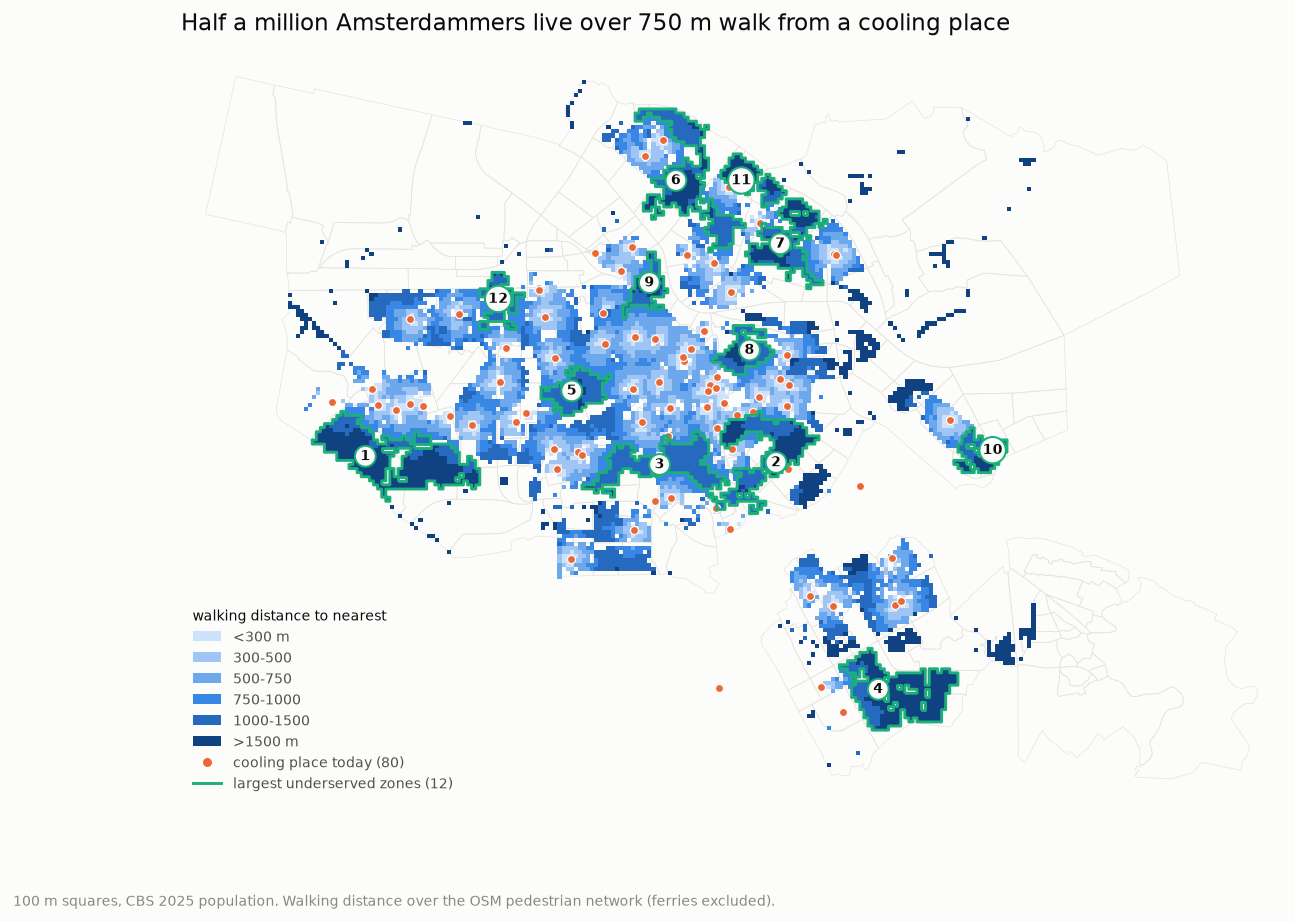

In [23]:
# near holds centroids; rejoin the original square polygons for an honest choropleth.
squares = grid.merge(near[["crs28992res100m", "net_m"]], on="crs28992res100m", how="inner")

bands = [0, 300, 500, 750, 1000, 1500, 1e9]
labels = ["<300 m", "300-500", "500-750", "750-1000", "1000-1500", ">1500 m"]
norm = BoundaryNorm(bands, len(RAMP))

# Size the figure to the data's own aspect ratio. Otherwise an equal-aspect map floats in a
# band of empty space, which reads as a rendering mistake.
minx, miny, maxx, maxy = b.total_bounds
pad = 600
aspect = ((maxy - miny) + 2 * pad) / ((maxx - minx) + 2 * pad)
fig, ax = plt.subplots(figsize=(11, 11 * aspect))

b.boundary.plot(ax=ax, color="#e6e4de", linewidth=0.4, zorder=1)
squares.plot(ax=ax, column="net_m", cmap=ListedColormap(RAMP), norm=norm, zorder=2)
facilities.plot(ax=ax, color=ORANGE, markersize=20, edgecolor=SURFACE, linewidth=0.7, zorder=3)
top.boundary.plot(ax=ax, color=AQUA, linewidth=1.6, zorder=4)

# Numbered to match figure 8c, so the zones are identifiable without relying on colour - which
# is also what the palette's contrast warning on aqua requires. representative_point() is
# guaranteed to fall INSIDE the polygon; a centroid is not, for concave shapes like these.
for rank, geom in zip(top.index, top.geometry):
    p = geom.representative_point()
    ax.annotate(str(rank), (p.x, p.y), color=INK, fontsize=8, fontweight="bold",
                ha="center", va="center", zorder=5,
                bbox=dict(boxstyle="circle,pad=0.22", facecolor=SURFACE, edgecolor=AQUA, linewidth=1.1))

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in RAMP] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=ORANGE,
           markeredgecolor=SURFACE, markersize=6, label=f"cooling place today ({len(facilities)})"),
    Line2D([], [], color=AQUA, linewidth=1.6, label="largest underserved zones (12)"),
]
ax.legend(handles, labels + [h.get_label() for h in handles[-2:]],
          loc="lower left", frameon=False, fontsize=8, labelcolor=INK_2,
          title="walking distance to nearest", title_fontsize=8, alignment="left",
          borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_title("Half a million Amsterdammers live over 750 m walk from a cooling place",
             fontsize=13, color=INK, loc="left", pad=12)
ax.set_axis_off()
ax.set_aspect("equal")
fig.text(0.01, 0.005, "100 m squares, CBS 2025 population. Walking distance over the OSM "
         "pedestrian network (ferries excluded).", fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "coverage_map.png")
plt.show()


### 8b. How much the method mattered

The same city measured two ways. This is the chart that justifies section 6 existing.


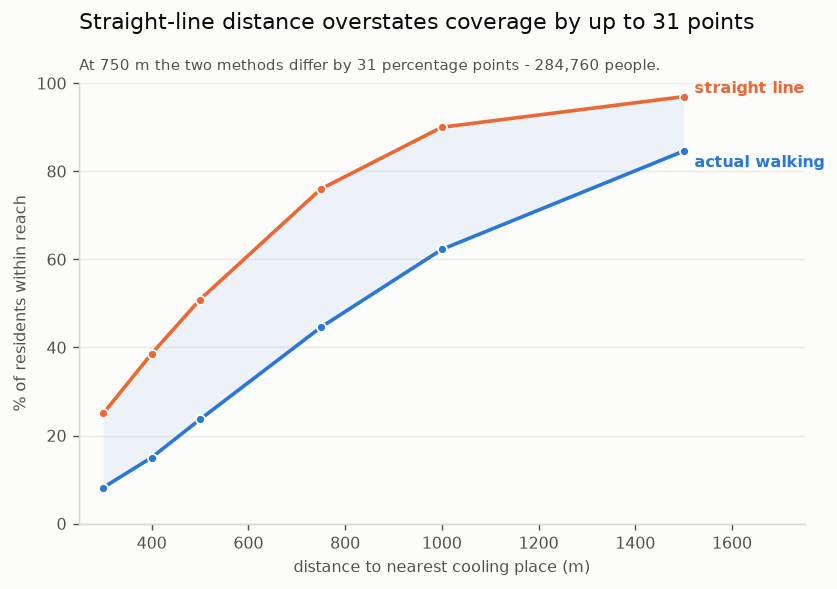

In [24]:
thresholds = [300, 400, 500, 750, 1000, 1500]
r = near[near["net_m"].notna()]
tot = r[POP].sum()
straight = [r.loc[r["dist_m"] <= t, POP].sum() / tot * 100 for t in thresholds]
network = [r.loc[r["net_m"] <= t, POP].sum() / tot * 100 for t in thresholds]

fig, ax = plt.subplots(figsize=(7.2, 4.4))

ax.fill_between(thresholds, network, straight, color=BLUE, alpha=0.07, linewidth=0)
ax.plot(thresholds, straight, color=ORANGE, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1)
ax.plot(thresholds, network, color=BLUE, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1)

ax.annotate("straight line", (thresholds[-1], straight[-1]), xytext=(6, 2),
            textcoords="offset points", color=ORANGE, fontsize=9, fontweight="bold")
ax.annotate("actual walking", (thresholds[-1], network[-1]), xytext=(6, -2),
            textcoords="offset points", color=BLUE, fontsize=9, fontweight="bold", va="top")

# A subtitle rather than an in-plot annotation: at every position tried, the label collided
# with one of the two lines. Text that has to dodge the data belongs outside the plot.
i = thresholds.index(750)
# NOT `gap` - section 7 binds that name to the underserved-squares frame, and a notebook
# shares one namespace across every cell.
gap_pp = straight[i] - network[i]
ax.text(0, 1.03, f"At 750 m the two methods differ by {gap_pp:.0f} percentage points - "
        f"{gap_pp / 100 * tot:,.0f} people.",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)

ax.set_xlabel("distance to nearest cooling place (m)")
ax.set_ylabel("% of residents within reach")
ax.set_ylim(0, 100)
ax.set_xlim(250, 1750)
ax.grid(axis="y", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.set_title("Straight-line distance overstates coverage by up to 31 points",
             fontsize=12, color=INK, loc="left", pad=30)
fig.savefig(FIGS / "coverage_curve.png")
plt.show()


### 8c. How big the gaps are

Twelve zones hold 70% of everyone beyond a 1,000 m walk. The long tail - 141 zones under 500
residents each - is a rounding error, and worth showing as such rather than ranking.


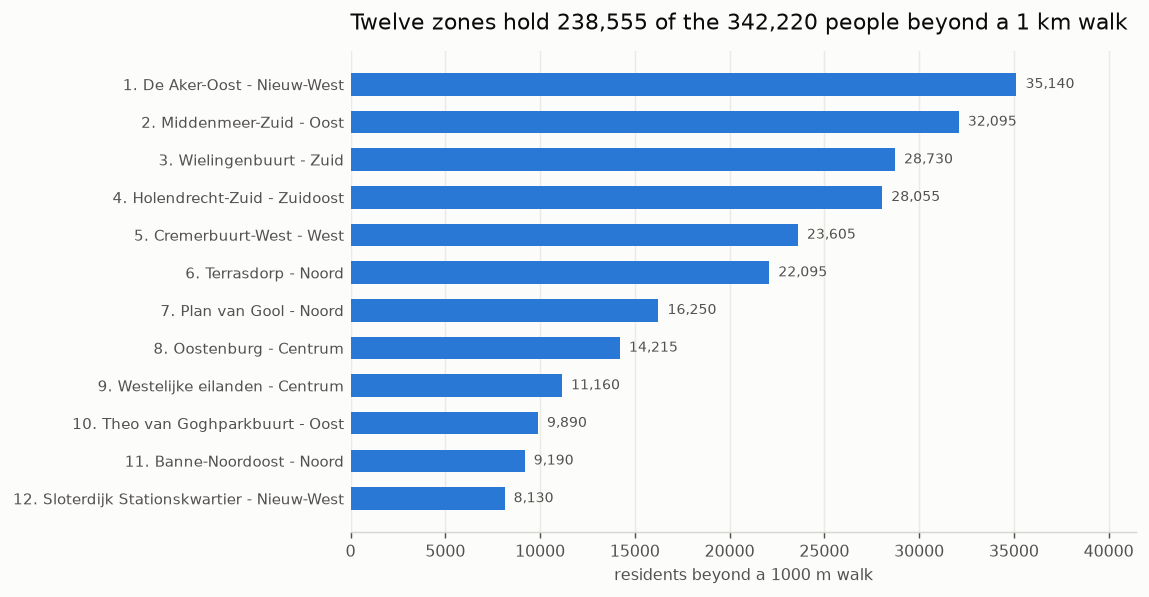

In [25]:
fig, ax = plt.subplots(figsize=(7.8, 4.8))

order = top.iloc[::-1]  # matplotlib draws bottom-up
y = range(len(order))
ax.barh(y, order["residents"], color=BLUE, height=0.6)

# Numbered to match the map, so a reader can move between the two figures.
ax.set_yticks(list(y))
ax.set_yticklabels([f"{r}. {b.split(',')[0]} - {sd}"
                    for r, b, sd in zip(order.index, order["buurten"], order["stadsdeel"])],
                   fontsize=8.5)

for yi, v in zip(y, order["residents"]):
    ax.annotate(f"{v:,.0f}", (v, yi), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)

ax.set_xlabel(f"residents beyond a {RADIUS} m walk")
ax.set_xlim(0, top["residents"].max() * 1.18)
ax.grid(axis="x", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Twelve zones hold {top['residents'].sum():,.0f} of the {zones['residents'].sum():,.0f} "
             "people beyond a 1 km walk", fontsize=12, color=INK, loc="left", pad=12)
fig.savefig(FIGS / "underserved_zones.png")
plt.show()


## 9. Vulnerability: who is underserved, not just how many

Every figure so far counts residents equally. Heat does not. Mortality during heatwaves
concentrates sharply in the over-65s, and the same group walks slowest - which is the
assumption the 500 m threshold rests on. So the question is whether the people most at risk
are also the worst served.

### Handling suppression honestly

`aantal_inwoners_65_jaar_en_ouder` is suppressed in **23% of populated squares** - but those
squares hold only ~12% of the population, because suppression means "fewer than 5", and a
square with few elderly is exactly the kind that gets withheld.

That non-randomness is the trap. Dropping suppressed squares would systematically remove the
*low*-elderly ones and inflate every elderly share. Imputing a value would invent data.

Instead, exploit the fact that the unknown is **bounded**: a suppressed count is 0-4. Compute
every figure twice - once with all suppressed values at 0, once at 4 - and report the
interval. If the conclusion survives both extremes it is robust, and no imputation was needed
to get there.


In [26]:
eld_lo = near[ELDERLY].fillna(0)   # every suppressed square holds zero over-65s
eld_hi = near[ELDERLY].fillna(4)   # every suppressed square holds four

print(f"{near[ELDERLY].isna().sum():,} of {len(near):,} squares suppressed "
      f"({near.loc[near[ELDERLY].isna(), POP].sum() / near[POP].sum():.0%} of residents)")
print(f"65+ population: {eld_lo.sum():,.0f} to {eld_hi.sum():,.0f}")
print(f"share of all residents: {eld_lo.sum() / near[POP].sum():.1%} to "
      f"{eld_hi.sum() / near[POP].sum():.1%}")

# Sanity check: Amsterdam is a young city, roughly 13-14% over 65. A result far outside that
# would mean the column or the suppression handling is wrong.
assert 0.10 < eld_lo.sum() / near[POP].sum() < 0.20


1,605 of 7,043 squares suppressed (11% of residents)
65+ population: 122,365 to 128,785
share of all residents: 13.5% to 14.2%


### 9a. Are the elderly worse served?


In [27]:
print(f"{'':>7}{'all residents':>15}{'65+ (low)':>12}{'65+ (high)':>12}")
for t in (300, 400, 500, 750, 1000, 1500):
    m = near["net_m"] <= t
    print(f"{t:>5} m {near.loc[m, POP].sum() / near[POP].sum():>14.1%}"
          f"{eld_lo[m].sum() / eld_lo.sum():>12.1%}{eld_hi[m].sum() / eld_hi.sum():>12.1%}")


         all residents   65+ (low)  65+ (high)
  300 m           8.2%        8.6%        8.4%
  400 m          15.0%       15.1%       14.8%
  500 m          23.7%       22.9%       22.5%
  750 m          44.6%       43.6%       42.9%
 1000 m          62.3%       61.4%       60.6%
 1500 m          84.6%       84.0%       83.4%


**City-wide, no. The curves are within a percentage point of each other at every threshold**
(22.9-22.5% of over-65s within 500 m against 23.7% of everyone), and the low and high bounds
differ by under half a point - so the answer does not depend on how suppression is treated.

That is a real finding, and a negative one: the existing 80 cooling places are neither
well-targeted at the vulnerable population nor badly targeted. They are simply distributed
like the population.

Worth stating plainly rather than dressing up. A null result at city level is not a failed
analysis - it rules out one explanation and pushes the question down a level.


### 9b. Where it does change the answer

The city-level null hides real local variation: elderly share across the underserved zones
ranges from 12% to 23%. Ranking the same zones by *who* lives in them rather than *how many*
reorders the priorities.


In [28]:
zone_eld = gap.assign(eld_lo=gap[ELDERLY].fillna(0), eld_hi=gap[ELDERLY].fillna(4)).groupby("zone").agg(
    residents=(POP, "sum"),
    eld_lo=("eld_lo", "sum"),
    eld_hi=("eld_hi", "sum"),
)
zone_eld["eld_share"] = zone_eld["eld_lo"] / zone_eld["residents"]
zone_eld = zone_eld.join(zones[["stadsdeel", "buurten"]])

by_age = zone_eld.sort_values("eld_lo", ascending=False).head(12)
by_age.round({"residents": 0, "eld_lo": 0, "eld_hi": 0, "eld_share": 3})


,residents,eld_lo,eld_hi,eld_share,stadsdeel,buurten
zone,,,,,,
130,28055.0,5510.0,5594.0,0.196,Zuidoost,"Holendrecht-Zuid, Gein 4, Gein 3"
0,35140.0,5380.0,5680.0,0.153,Nieuw-West,"De Aker-Oost, De Aker-West, Middelveldsche Ake..."
62,28730.0,4560.0,4668.0,0.159,Zuid,"Wielingenbuurt, IJselbuurt-West, IJselbuurt-Oost"
96,32095.0,4190.0,4350.0,0.131,Oost,"Middenmeer-Zuid, Transvaalbuurt-Oost, Tuindorp..."
110,16250.0,3290.0,3406.0,0.202,Noord,"Plan van Gool, Buikslotermeer-Noord, De Kleine..."
44,23605.0,3145.0,3153.0,0.133,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
88,22095.0,2680.0,3052.0,0.121,Noord,"Terrasdorp, NDSM terrein, De Bongerd"
87,11160.0,2375.0,2395.0,0.213,Centrum,"Westelijke eilanden, Haarlemmerbuurt-West, Wes..."
98,14215.0,2205.0,2269.0,0.155,Centrum,"Oostenburg, Wittenburg, Kadijken"


Holendrecht-Zuid / Gein in Zuidoost moves from **4th by population to 1st by elderly
population** - 5,510 over-65s, a 20% elderly share, and the worst mean walk of any zone at
2.4 km. Plan van Gool in Noord (20% elderly) rises from 7th to 5th. Small zones with high
concentration surface too: Betondorp in Oost is only 4,435 residents but 23% of them are over
65.

If the city could act on one zone, the population ranking says De Aker and the age ranking
says Holendrecht/Gein. The second is the better answer, and only the vulnerability weighting
surfaces it.


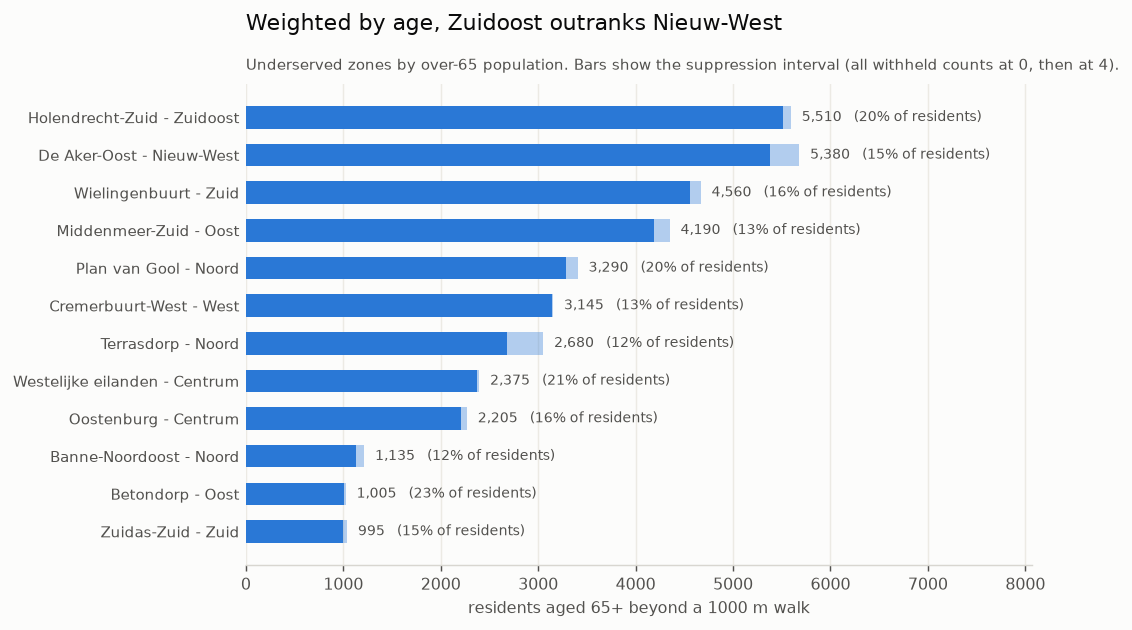

In [29]:
fig, ax = plt.subplots(figsize=(7.8, 4.8))

order = by_age.iloc[::-1]
y = range(len(order))
ax.barh(y, order["eld_lo"], color=BLUE, height=0.6)

# The uncertainty from suppression, drawn rather than described. It is barely visible - which
# is the point: the bounds are tight enough that the ranking does not depend on them.
ax.barh(y, order["eld_hi"] - order["eld_lo"], left=order["eld_lo"], color=BLUE,
        alpha=0.35, height=0.6)

ax.set_yticks(list(y))
ax.set_yticklabels([f"{b.split(',')[0]} - {sd}"
                    for b, sd in zip(order["buurten"], order["stadsdeel"])], fontsize=8.5)

# Anchor the label to the UPPER bound, not the solid bar, or it sits on top of the pale
# uncertainty segment.
for yi, (lo, hi, share) in enumerate(zip(order["eld_lo"], order["eld_hi"], order["eld_share"])):
    ax.annotate(f"{lo:,.0f}   ({share:.0%} of residents)", (hi, yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK_2)

ax.set_xlabel(f"residents aged 65+ beyond a {RADIUS} m walk")
ax.set_xlim(0, by_age["eld_hi"].max() * 1.42)
ax.grid(axis="x", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Weighted by age, Zuidoost outranks Nieuw-West",
             fontsize=12, color=INK, loc="left", pad=30)
ax.text(0, 1.03, "Underserved zones by over-65 population. Bars show the suppression "
        "interval (all withheld counts at 0, then at 4).",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "vulnerability_zones.png")
plt.show()


### What this does not cover

- **Income and social security.** `aantal_personen_met_uitkering_onder_aowlft` is suppressed in
  54% of squares, covering only 71% of residents. Usable at buurt level, not at 100 m.
- **Living alone**, a documented heat-mortality risk factor, is available (26% suppressed,
  92% of residents) and would be the natural next axis.
- **Housing quality.** Pre-1945 building stock is 71% suppressed - not usable here.
- **Facility capacity.** A library and a supermarket cafe still count the same.


## 10. A second sensitivity axis: living alone

Age is not the only thing that kills people in a heatwave. Social isolation is one of the
strongest independent predictors - the post-mortems of the 2003 European heatwave found that
an elderly person with someone checking on them was in a different risk class from one
without. CBS publishes single-person household counts per square, so this axis is available
at the same 100 m resolution as everything else.

Suppression here is milder than for age: within the demand squares, 15% for single-person
households and 4% for the household total.


In [30]:
alone = near[ALONE].fillna(0)

both = near[ALONE].notna() & near[HOUSEHOLDS].notna() & (near[HOUSEHOLDS] > 0)
print(f"both counts known in {both.mean():.0%} of squares "
      f"({near.loc[both, POP].sum() / near[POP].sum():.0%} of residents)")
print(f"{alone.sum():,.0f} people live alone "
      f"({alone.sum() / near[POP].sum():.0%} of residents)")

# Each single-person household is exactly one person, so this count is directly comparable
# with the population weights above - unlike a household count for larger households.
for label, w in [("all residents", near[POP]), ("65+", eld_lo), ("living alone", alone)]:
    c500 = w[near["net_m"] <= 500].sum() / w.sum()
    c1k = w[near["net_m"] <= 1000].sum() / w.sum()
    print(f"{label:<16} within 500 m {c500:>6.1%}   within 1000 m {c1k:>6.1%}")


both counts known in 85% of squares (96% of residents)
276,530 people live alone (30% of residents)
all residents    within 500 m  23.7%   within 1000 m  62.3%
65+              within 500 m  22.9%   within 1000 m  61.4%
living alone     within 500 m  26.1%   within 1000 m  66.4%


**People living alone are slightly *better* served than average** - 26.1% within 500 m
against 23.7% overall. Not a paradox: single-person households concentrate in the dense
centre and pre-war ring, which is exactly where the cooling places are. Isolation and
inaccessibility are negatively correlated in Amsterdam.

That is the second null in a row, and it is worth taking seriously rather than hunting for a
weighting that produces a gradient. Neither age nor isolation predicts access. The 80
cooling places track population density, and population density is what they track.


### 10a. The interaction we cannot measure

The variable that actually matters is **elderly people living alone** - the two risk factors
together. CBS publishes the two counts per square but not the cross-tabulation, so the
overlap has to be bounded rather than measured.

Per square the bounds are elementary: the overlap is at least `65+ plus living-alone minus
total residents` (they cannot both fit otherwise) and at most the smaller of the two.


In [31]:
lo = np.maximum(0, near[ELDERLY].fillna(0) + alone - near[POP])
hi = np.minimum(near[ELDERLY].fillna(0), alone)

print(f"elderly living alone: between {lo.sum():,.0f} and {hi.sum():,.0f}")
print(f"  for reference: {eld_lo.sum():,.0f} people are 65+, {alone.sum():,.0f} live alone")


elderly living alone: between 2,920 and 108,830
  for reference: 122,365 people are 65+, 276,530 live alone


**Between 2,920 and 108,830 - a 37-fold range.** The bounds are useless, and that is the
honest result: this data cannot answer the question. The same bounding technique that worked
for suppression in section 9 fails here, because suppression was a *narrow* unknown (0-4 per
square) while an unobserved cross-tabulation is a *wide* one.

So the interaction is not reported. The route to it, if it matters enough, is a CBS StatLine
table of household composition by age at buurt or wijk level - apply that conditional
probability to the squares, and state it as an assumption rather than a measurement.

Worth being clear about what happened here: computing the bounds took two lines and told us
not to trust an analysis we would otherwise have produced. A weighted "isolation-adjusted
elderly" score would have looked perfectly plausible and been meaningless.


## 11. Exposure: how hot is it where they live?

Sections 9 and 10 add *who*. This adds *where* - and it is the axis the analysis was missing
entirely. Until now every square was treated as equally hot.

**What we can and cannot compute.** The gemeente's Klimaatrisicokaarten carry a real PET
(physiological equivalent temperature) score, modelled from building geometry, albedo, wind
and radiation. We cannot reproduce that, and should not pretend to. What is computable from
primary open data is **surface cover**: how much of each 100 m square is vegetation or water
rather than stone. That is the physical driver behind the urban heat island - stone stores
heat, vegetation evaporates it - so it is a defensible *proxy*, labelled as one, and not a
temperature.

Source: **BGT** (Basisregistratie Grootschalige Topografie) via the PDOK download API - the
same national base the municipal maps are built from, so this is rebuilt from their upstream
rather than copied from their output.


### 11a. Getting the data

The BGT OGC API is not usable at this scale: `pand` and `onbegroeidterreindeel` both hit the
1,000-feature page cap inside a single 0.8 km2 box. Use the asynchronous bulk extract instead.

```bash
# POST a job (geofilter = a SINGLE-RING polygon in EPSG:28992; MultiPolygons are rejected,
# so Amsterdam's mainland and Weesp need one request each)
curl -X POST https://api.pdok.nl/lv/bgt/download/v1_0/full/custom \
  -H 'Content-Type: application/json' \
  -d '{"featuretypes":["begroeidterreindeel","waterdeel"],
       "format":"citygml","geofilter":"POLYGON((...))"}'
# poll  /full/custom/{id}/status  until COMPLETED, then GET the download href
```

Three traps, all of which silently corrupt the result rather than erroring:

1. **The extract contains history.** Only ~40% of the vegetation records are current
   (88,819 of 219,399 for the mainland). Filter `eindRegistratie` null and
   `bgt-status == "bestaand"`, or you will count lawns that were paved over years ago.
2. **`relatieveHoogteligging != 0` must go.** A bridge deck over a canal would otherwise
   cover the water beneath it and both would count.
3. **The GML declares an unknown geometry type** (`-2147483648`) that pyogrio refuses. GDAL
   writes a `.gfs` schema sidecar on first read; setting `<GeometryType>3</GeometryType>`
   in it makes every subsequent read work. Field names in the GML are camelCase
   (`eindRegistratie`), unlike the snake_case the OGC API returns for the same data.


In [32]:
import glob

COVER = PROCESSED / "surface_cover.csv"

if COVER.exists():
    cover = pd.read_csv(COVER)
else:
    # squares as polygons (near holds centroids)
    poly = grid[grid["crs28992res100m"].isin(set(near["crs28992res100m"]))][
        ["crs28992res100m", "geometry"]
    ].reset_index(drop=True)

    acc = {}
    for path in sorted(glob.glob("data/raw/bgt/*/bgt_*.gml")):
        kind = "water" if "waterdeel" in path else "green"
        df = gpd.read_file(path, layer=0, force_2d=True,
                           columns=["class", "eindRegistratie", "bgt-status",
                                    "relatieveHoogteligging"])
        df = df[df["eindRegistratie"].isna()]
        df = df[df["bgt-status"] == "bestaand"]
        df = df[df["relatieveHoogteligging"] == 0]
        df = df[df.geometry.notna() & ~df.geometry.is_empty].set_crs(RD, allow_override=True)

        # sjoin finds candidate pairs; .intersection then gives the actual overlap area.
        # Doing it this way rather than gpd.overlay keeps 100k+ polygons tractable.
        j = gpd.sjoin(df[["geometry"]], poly, predicate="intersects")
        other = poly.geometry.values[j["index_right"].values]
        inter = gpd.GeoSeries(j.geometry.values, crs=RD).intersection(
            gpd.GeoSeries(other, crs=RD))
        s = pd.Series(inter.area.values).groupby(j["crs28992res100m"].values).sum()
        d = acc.setdefault(kind, {})
        for k, v in s.items():
            d[k] = d.get(k, 0.0) + v

    cover = poly[["crs28992res100m"]].copy()
    for kind in ("green", "water"):
        cover[f"{kind}_m2"] = cover["crs28992res100m"].map(acc.get(kind, {})).fillna(0.0)
    # Polygons within a layer can overlap slightly, so clip rather than trust the sum.
    for c, col in [("green_frac", "green_m2"), ("water_frac", "water_m2")]:
        cover[c] = (cover[col] / 10_000).clip(0, 1)
    cover["greenblue_frac"] = ((cover["green_m2"] + cover["water_m2"]) / 10_000).clip(0, 1)
    cover.to_csv(COVER, index=False)

near = near.merge(cover[["crs28992res100m", "green_frac", "water_frac", "greenblue_frac"]],
                  on="crs28992res100m", how="left")
near["stony"] = 1 - near["greenblue_frac"]
assert near["greenblue_frac"].notna().all()
print(near[["green_frac", "water_frac", "greenblue_frac"]].describe().round(3))


       green_frac  water_frac  greenblue_frac
count    7043.000    7043.000        7043.000
mean        0.156       0.098           0.254
std         0.165       0.169           0.226
min         0.000       0.000           0.000
25%         0.013       0.000           0.060
50%         0.108       0.000           0.206
75%         0.247       0.137           0.384
max         1.000       1.000           1.000


### 11b. Access and exposure run in opposite directions

This is the question the whole section exists to answer: are the underserved areas also the
hot ones?


In [33]:
print("correlation, walking distance vs green-blue fraction:",
      round(near["net_m"].corr(near["greenblue_frac"]), 3))

q = pd.qcut(near["net_m"], 5, labels=["nearest", "2", "3", "4", "farthest"])
print("\nmean green-blue fraction by distance-to-cooling quintile:")
print(near.groupby(q, observed=True)["greenblue_frac"].mean().round(3).to_string())

near["stony_q"] = pd.qcut(near["stony"], 4, labels=["greenest", "3", "2", "stoniest"])
print("\ncoverage by stoniness quartile:")
for lab, g in near.groupby("stony_q", observed=True):
    print(f"  {lab:<9}{g[POP].sum():>9,.0f} residents"
          f"   within 500 m {g.loc[g['net_m'] <= 500, POP].sum() / g[POP].sum():>6.1%}"
          f"   within 1 km {g.loc[g['net_m'] <= 1000, POP].sum() / g[POP].sum():>6.1%}")


correlation, walking distance vs green-blue fraction: 0.208

mean green-blue fraction by distance-to-cooling quintile:
net_m
nearest     0.189
2           0.225
3           0.253
4           0.273
farthest    0.330

coverage by stoniness quartile:
  greenest   120,425 residents   within 500 m  14.8%   within 1 km  50.3%
  3          201,355 residents   within 500 m  20.3%   within 1 km  58.4%
  2          245,635 residents   within 500 m  24.1%   within 1 km  60.8%
  stoniest   339,360 residents   within 500 m  28.5%   within 1 km  69.8%


**The two axes are inverted.** Green-blue cover rises monotonically with distance from a
cooling place - 18.9% in the nearest quintile to 33.0% in the farthest - and the *stoniest*
quartile of the city has the *best* coverage (28.5% within 500 m) while the greenest has the
worst (14.8%).

The mechanism is not mysterious: cooling places are in dense central neighbourhoods because
that is where the libraries, community centres and supermarkets are, and dense central
neighbourhoods are stone. The green edges of the city are underserved *and* cooler.

This materially weakens the naive ranking. De Aker - top of section 7 by population - is
26.8% green-blue, well above the median. It is far from a cooling place and it is one of the
cooler places to be far from one.

It also means "distance to cooling" and "need for cooling" really are different maps, which
is worth stating as a result in its own right rather than buried as a caveat.


### 11c. The intersection

Three axes, kept separate and combined by *filtering*, not by weighting. Each condition is
defensible alone, and the count of people meeting all of them is a number to stand behind.

A composite score would let one axis silently compensate for another - a very green area
could outrank a stony one on distance alone, which is exactly the error to avoid here.


In [34]:
underserved = near["net_m"] > RADIUS
stonier = near["stony"] >= near["stony"].median()

print(f"underserved (>{RADIUS} m):              {near.loc[underserved, POP].sum():>9,.0f}")
print(f"  ...and stonier than median:      {near.loc[underserved & stonier, POP].sum():>9,.0f}")

# Zones re-ranked: residents who are BOTH beyond the radius and in a stonier-than-median square.
gap_stony = gap.merge(cover[["crs28992res100m", "greenblue_frac"]], on="crs28992res100m")
gap_stony["stony"] = 1 - gap_stony["greenblue_frac"]
hot_gap = gap_stony[gap_stony["stony"] >= near["stony"].median()]

zone_hot = (hot_gap.groupby("zone")
            .agg(stony_residents=(POP, "sum"), mean_greenblue=("greenblue_frac", "mean"))
            .join(zones[["residents", "stadsdeel", "buurten"]])
            .sort_values("stony_residents", ascending=False))

zone_hot.head(12).round({"stony_residents": 0, "mean_greenblue": 3, "residents": 0})


underserved (>1000 m):                342,220
  ...and stonier than median:        198,850


,stony_residents,mean_greenblue,residents,stadsdeel,buurten
zone,,,,,
62,26280.0,0.054,28730.0,Zuid,"Wielingenbuurt, IJselbuurt-West, IJselbuurt-Oost"
96,24350.0,0.076,32095.0,Oost,"Middenmeer-Zuid, Transvaalbuurt-Oost, Tuindorp..."
0,20320.0,0.092,35140.0,Nieuw-West,"De Aker-Oost, De Aker-West, Middelveldsche Ake..."
44,19785.0,0.038,23605.0,West,"Cremerbuurt-West, Paramariboplein e.o., Borger..."
88,14865.0,0.085,22095.0,Noord,"Terrasdorp, NDSM terrein, De Bongerd"
130,9960.0,0.108,28055.0,Zuidoost,"Holendrecht-Zuid, Gein 4, Gein 3"
98,8800.0,0.081,14215.0,Centrum,"Oostenburg, Wittenburg, Kadijken"
176,6450.0,0.074,9890.0,Oost,"Theo van Goghparkbuurt, Havenkwartier IJburg, ..."
110,6185.0,0.103,16250.0,Noord,"Plan van Gool, Buikslotermeer-Noord, De Kleine..."


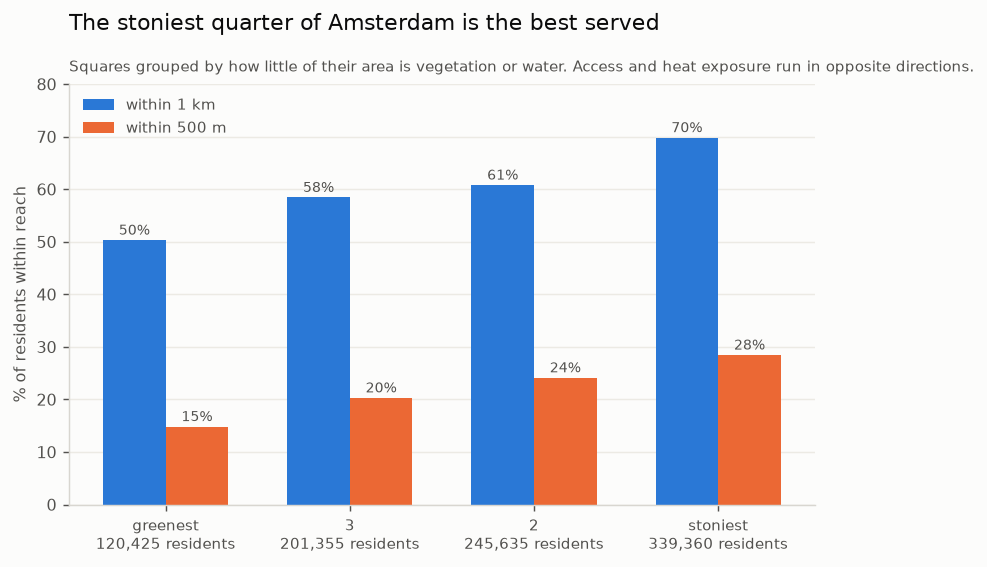

In [35]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))

labels = ["greenest", "3", "2", "stoniest"]
c500, c1k, pops = [], [], []
for lab in labels:
    g = near[near["stony_q"] == lab]
    pops.append(g[POP].sum())
    c500.append(g.loc[g["net_m"] <= 500, POP].sum() / g[POP].sum() * 100)
    c1k.append(g.loc[g["net_m"] <= 1000, POP].sum() / g[POP].sum() * 100)

x = np.arange(len(labels))
w = 0.34
ax.bar(x - w / 2, c1k, w, color=BLUE, label="within 1 km")
ax.bar(x + w / 2, c500, w, color=ORANGE, label="within 500 m")

# NOT (a, b): `b` is the buurten GeoDataFrame. A loop variable in a notebook clobbers it for
# every later cell, and the failure surfaces sections away from the cause.
for xi, (v_1k, v_500) in enumerate(zip(c1k, c500)):
    ax.annotate(f"{v_1k:.0f}%", (xi - w / 2, v_1k), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2)
    ax.annotate(f"{v_500:.0f}%", (xi + w / 2, v_500), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2)

ax.set_xticks(x)
ax.set_xticklabels([f"{l}\n{p:,.0f} residents" for l, p in zip(labels, pops)], fontsize=8.5)
ax.set_ylabel("% of residents within reach")
ax.set_ylim(0, 80)
ax.grid(axis="y", color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left")
ax.set_title("The stoniest quarter of Amsterdam is the best served",
             fontsize=12, color=INK, loc="left", pad=30)
ax.text(0, 1.03, "Squares grouped by how little of their area is vegetation or water. "
        "Access and heat exposure run in opposite directions.",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "exposure_coverage.png")
plt.show()


### What this proxy does not capture

- **It is not PET.** No building height, albedo, wind or radiation. A narrow stone street with
  tall buildings is shaded for much of the day; a wide stone plaza is not. This measure cannot
  tell them apart.
- **Water cools locally but you cannot sit on it.** Green and blue are pooled here; the
  correlation with green alone is weaker (0.159 against 0.208) but runs the same way.
- **Tree canopy is invisible.** BGT records ground cover, so a paved street under a full tree
  canopy scores as stone. The tree register or an AHN-derived shade model would fix this and
  is the natural next step.
- **Density confounds it.** Green squares are low-density, so they hold fewer people - which
  is why the population-weighted table matters more than the square counts.


## 12. Dwelling overheating (TOjuli)

Section 11 measures how hot it is *outside*. This measures whether the *home* is liveable -
which is closer to the mechanism, because heat mortality is driven substantially by indoor
night-time temperature, not street conditions.

**TOjuli** (`Temperatuuroverschrijding` in the export) is the NTA 8800 summer
temperature-exceedance indicator: the modelled risk that a dwelling without active cooling
overheats. It is computed per home by a national standard as part of the energy label. That
makes it categorically better than anything we could construct - there is no proxy to justify
and no weights to defend.

Source: EP-Online public data (RVO), monthly full file, requires a free API key. Amsterdam +
Weesp postcodes: 1000-1109 **and 1380-1384** - Weesp was annexed in 2022 and sits outside the
old Amsterdam range. Omitting it silently drops ~11,700 dwellings; it cost us one wrong
coverage figure before it was caught.


### 12a. Exclusions, stated first

- **`TOjuli > 10`** - data errors. The maximum in the file is 324 and 15 rows carry a
  requirement threshold of 450. 306 dwellings dropped.
- **`TOjuli == 0`** - means *actively cooled*, not "does not overheat". Scoring it as low
  risk would make the air-conditioned stock look like the safest housing in the city. Held out
  as a separate category: 21,065 dwellings.

The NTA 8800 requirement threshold is **1.20**; higher is worse.


In [36]:
EP_FILE = RAW / "v20260901_v4_csv.csv"        # EP-Online monthly full file
BAG_FILE = RAW / "bag-light.gpkg"
OVERHEAT = PROCESSED / "dwelling_overheating.csv"

AMS_PC4 = set(range(1000, 1110)) | set(range(1380, 1385))   # incl. Weesp

if OVERHEAT.exists():
    overheat = pd.read_csv(OVERHEAT)
else:
    # --- energy labels: 6.2M national rows, read in chunks and filtered to Amsterdam
    cols = ["Postcode", "BAGVerblijfsobjectID", "Gebouwklasse", "Gebouwsubtype",
            "Temperatuuroverschrijding", "Registratiedatum"]
    parts = []
    for chunk in pd.read_csv(EP_FILE, sep=";", skiprows=2, usecols=cols, dtype=str,
                             chunksize=500_000, on_bad_lines="skip", low_memory=False):
        pc4 = pd.to_numeric(chunk["Postcode"].str[:4], errors="coerce")
        parts.append(chunk[pc4.isin(AMS_PC4)])
    ep = pd.concat(parts, ignore_index=True)
    ep = ep[ep["Gebouwklasse"] == "W"]                       # residential only
    ep["TOjuli"] = pd.to_numeric(
        ep["Temperatuuroverschrijding"].str.replace(",", ".", regex=False), errors="coerce")
    ep = ep.dropna(subset=["BAGVerblijfsobjectID"]).drop_duplicates("BAGVerblijfsobjectID")

    # --- BAG dwellings (7.8 GB national GeoPackage, bbox-filtered at read time)
    vbo = gpd.read_file(BAG_FILE, layer="verblijfsobject", bbox=tuple(b.total_bounds),
                        columns=["identificatie", "status", "gebruiksdoel", "woonplaats_naam"])
    vbo = vbo[vbo["woonplaats_naam"].isin(["Amsterdam", "Weesp"])]
    vbo = vbo[vbo["status"].str.contains("in gebruik", na=False)]
    vbo = vbo[vbo["gebruiksdoel"].str.contains("woonfunctie", na=False)]

    # BAGVerblijfsobjectID is populated on 99.9% of labels, so this is an exact key join -
    # no address matching, no fuzzy strings.
    dw = vbo.merge(ep[["BAGVerblijfsobjectID", "TOjuli", "Gebouwsubtype"]],
                   left_on="identificatie", right_on="BAGVerblijfsobjectID", how="left")
    dw = dw[dw["TOjuli"].notna()]

    n_all = len(dw)
    dw = dw[dw["TOjuli"] <= 10]
    n_cooled = int((dw["TOjuli"] == 0).sum())
    dw = dw[dw["TOjuli"] > 0]
    print(f"{n_all:,} labelled | {n_all - len(dw) - n_cooled:,} data errors dropped | "
          f"{n_cooled:,} actively cooled held out | {len(dw):,} used")

    sq_poly = grid[grid["crs28992res100m"].isin(set(near["crs28992res100m"]))][
        ["crs28992res100m", "geometry"]].reset_index(drop=True)
    hit = gpd.sjoin(dw[["TOjuli", "geometry"]], sq_poly, predicate="within", how="inner")
    # Median, not mean: the distribution has a long right tail even after the >10 cut.
    overheat = (hit.groupby("crs28992res100m")
                .agg(tojuli=("TOjuli", "median"), n_labelled=("TOjuli", "size"))
                .reset_index())
    overheat.to_csv(OVERHEAT, index=False)

near = near.merge(overheat, on="crs28992res100m", how="left")
print(f"{near['tojuli'].notna().sum():,} of {len(near):,} squares have a TOjuli value")


6,159 of 7,043 squares have a TOjuli value


### 12b. Is the labelled sample good enough to use?

TOjuli exists only for dwellings labelled from 2021, when NTA 8800 replaced the older EI
method - so ~41% of Amsterdam's 494,801 dwellings have one. Three checks decide whether that
sample can carry a conclusion.

**1. Is coverage spatially even?** By stadsdeel it runs 37.7% to 46.2% - no meaningful skew.

**2. Are labelled dwellings different from unlabelled ones?** Within the same buurt they are
3 m2 *smaller* on average and identical in construction year. Build year matters far more for
overheating, so its absence from the comparison is the reassuring part.

**3. Does that difference move the answer?** Reweighting the labelled set to match the full
stock's floor-area profile shifts the median TOjuli from **1.700 to 1.680** - 0.02 on a scale
where the threshold is 1.20. The correlation between TOjuli and floor area is -0.032.

So the selection is real, small, and points slightly downward - meaning the raw figures are
mildly pessimistic. That is a footnote, not a caveat, and it is why this section uses TOjuli
alone rather than blending it with a structural estimate for the unlabelled half.


In [37]:
# Squares with too few labelled dwellings cannot support a median. Flag rather than drop
# silently - these hold a real share of the population.
MIN_LABELLED = 5
thin = near["n_labelled"].fillna(0) < MIN_LABELLED
print(f"{thin.sum():,} squares below {MIN_LABELLED} labelled dwellings "
      f"({near.loc[thin, POP].sum():,.0f} residents, {near.loc[thin, POP].sum() / near[POP].sum():.0%})")
print("labelled dwellings per usable square:",
      near.loc[~thin, "n_labelled"].describe()[["25%", "50%", "75%"]].round(0).to_dict())

ok = near[~thin]


2,137 squares below 5 labelled dwellings (141,425 residents, 16%)
labelled dwellings per usable square: {'25%': 11.0, '50%': 24.0, '75%': 48.0}


### 12c. The same inversion, from completely different data


In [38]:
print(f"correlation, walking distance vs median TOjuli: {ok['net_m'].corr(ok['tojuli']):.3f}")

q = pd.qcut(ok["net_m"], 5, labels=["nearest", "2", "3", "4", "farthest"])
print("\nmedian TOjuli by distance-to-cooling quintile:")
print(ok.groupby(q, observed=True)["tojuli"].median().round(2).to_string())

print("\nby stadsdeel:")
print(ok.groupby("stadsdeel")["tojuli"].median().round(2).sort_values(ascending=False).to_string())


correlation, walking distance vs median TOjuli: -0.120

median TOjuli by distance-to-cooling quintile:
net_m
nearest     1.93
2           1.91
3           1.82
4           1.77
farthest    1.58

by stadsdeel:
stadsdeel
Centrum       2.22
West          1.98
Oost          1.88
Zuid          1.81
Nieuw-West    1.74
Weesp         1.63
Noord         1.45
Zuidoost      1.42


**Correlation −0.120, and the quintiles fall monotonically: 1.93 nearest to 1.58 farthest.**

Section 11 found green cover *rising* with distance; this finds dwelling overheating *falling*
with distance. Same conclusion, opposite sign, entirely independent data - land cover from BGT
against building physics from NTA 8800.

Centrum has both the hottest dwellings (2.22) and the best access; Zuidoost (1.42) and Noord
(1.45) have the coolest housing and the worst. Amsterdam's cooling places are concentrated
where the overheating problem is, and thin where it is not.

Two independent measurements agreeing is the strongest evidence in this analysis. It also
means the headline is now firm: **the places furthest from a cooling place are not the places
that most need one.**


In [39]:
hot = ok["tojuli"] >= ok["tojuli"].median()
und = ok["net_m"] > RADIUS
eld_share = ok[ELDERLY].fillna(0) / ok[POP]
old = eld_share >= eld_share.median()

print(f"underserved (>{RADIUS} m):                       {ok.loc[und, POP].sum():>9,.0f}")
print(f"  ...AND overheating-prone dwellings:        {ok.loc[und & hot, POP].sum():>9,.0f}")
print(f"  ...AND also above-median elderly share:    {ok.loc[und & hot & old, POP].sum():>9,.0f}")

top = (ok[und & hot].groupby(["stadsdeel", "buurt"], as_index=False)
       .agg(residents=(POP, "sum"), tojuli=("tojuli", "median"))
       .sort_values("residents", ascending=False))
top.head(12).round({"residents": 0, "tojuli": 2})


underserved (>1000 m):                         266,860
  ...AND overheating-prone dwellings:          120,990
  ...AND also above-median elderly share:       52,645


,stadsdeel,buurt,residents,tojuli
111,West,Cremerbuurt-West,4620.0,2.10
101,Oost,Transvaalbuurt-Oost,4085.0,2.21
100,Oost,Theo van Goghparkbuurt,3170.0,2.34
40,Nieuw-West,Zuidwestkwadrant-Zuid,3005.0,2.76
108,West,Bellamybuurt-Zuid,2350.0,2.29
58,Noord,Plan van Gool,2250.0,2.43
4,Centrum,Kadijken,2135.0,2.02
123,West,Paramariboplein e.o.,2060.0,2.00
96,Oost,Sportheldenbuurt,2055.0,2.50
3,Centrum,Haarlemmerbuurt-West,2045.0,2.32


### 12d. Both measures on the same squares

The figure below computes **both** panels on `ok` - squares with at least five labelled
dwellings - so the two measures describe the same places. That matters: on this subset the
green-blue gradient reads 16% to 24%, weaker than the 18.9% to 33.0% in section 11.

The difference is the exclusion itself. Squares with too few labelled dwellings are sparse,
low-density and disproportionately **green**, so dropping them removes the greenest tail and
flattens that gradient. The direction is unchanged and the TOjuli gradient is unaffected, but
it is a reminder that a sample restriction imposed for one variable quietly reshapes every
other variable measured on the same rows.


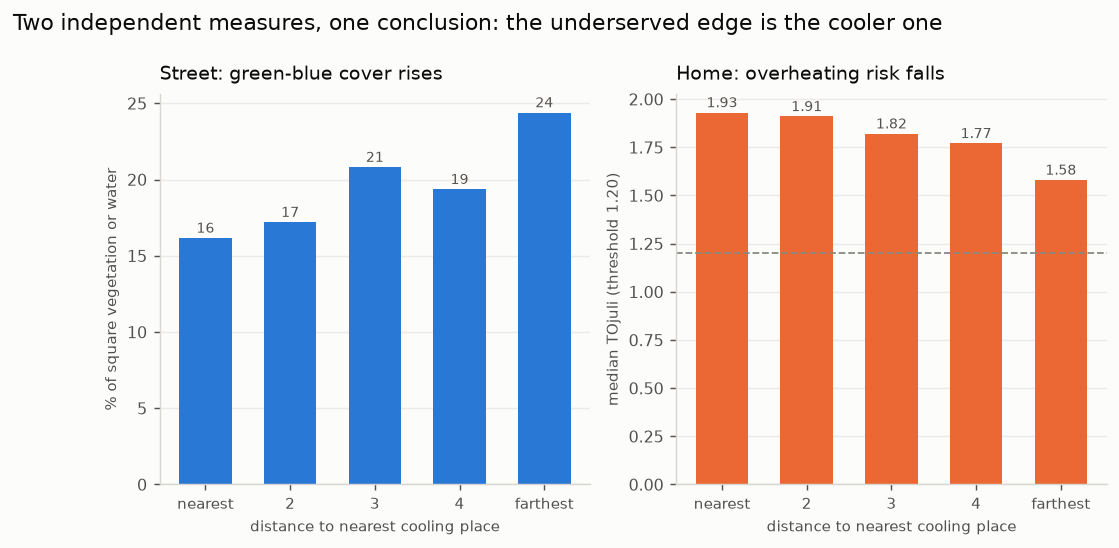

In [40]:
# Two exposure measures against the same x-axis. Small multiples rather than one chart with
# two y-scales - a dual axis would let the reader infer a relationship from line crossings
# that is an artefact of the scaling.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))

qs = ["nearest", "2", "3", "4", "farthest"]
gb = ok.groupby(q, observed=True)["greenblue_frac"].mean().reindex(qs) * 100
tj = ok.groupby(q, observed=True)["tojuli"].median().reindex(qs)

for ax, vals, title, ylab, colour in [
    (axes[0], gb, "Street: green-blue cover rises", "% of square vegetation or water", BLUE),
    (axes[1], tj, "Home: overheating risk falls", "median TOjuli (threshold 1.20)", ORANGE),
]:
    ax.bar(range(5), vals, 0.62, color=colour)
    for i, v in enumerate(vals):
        ax.annotate(f"{v:.2f}" if v < 10 else f"{v:.0f}", (i, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_2)
    ax.set_xticks(range(5))
    ax.set_xticklabels(qs, fontsize=8.5)
    ax.set_title(title, fontsize=10.5, color=INK, loc="left", pad=8)
    ax.set_ylabel(ylab, fontsize=8.5)
    ax.set_xlabel("distance to nearest cooling place", fontsize=8.5)
    ax.grid(axis="y", color="#eceae4", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[1].axhline(1.2, color=INK_3, linewidth=1, linestyle="--")

fig.suptitle("Two independent measures, one conclusion: the underserved edge is the cooler one",
             fontsize=12, color=INK, x=0.005, ha="left", y=1.04)
fig.savefig(FIGS / "exposure_two_measures.png")
plt.show()


### Limitations

- **41% of dwellings.** Only homes labelled from 2021 have TOjuli. Coverage is spatially even
  and the selection effect is 0.02 on the median, but 2,137 squares hold fewer than five
  labelled dwellings and are excluded - roughly 141,000 residents whose housing is unmeasured.
- **TOjuli is modelled, not measured.** It is an NTA 8800 calculation from building
  characteristics, not a thermometer. Its inputs are an assessor's inspection, with the
  variation that implies.
- **Actively cooled dwellings are held out, not scored.** 21,065 homes with mechanical cooling
  are absent from these medians. They are disproportionately new-build, so squares dominated
  by recent construction are measured on their uncooled minority.
- **Median hides the tail.** A square whose median is below the threshold can still contain
  many dwellings well above it - and it is individual homes that overheat, not medians.


## 13. Which underserved areas are actually vulnerable?

The goal here is understanding, not optimisation. Acquiring a cooling place is not the
binding constraint - agreements with libraries, community centres and shops are comparatively
cheap - so "maximum coverage from minimum sites" is the wrong objective. The useful question
is which underserved areas carry real need, and what kind of need.

Three axes are now available at 100 m: **access** (section 6), **exposure** (sections 11-12),
**vulnerability** (section 9). Each underserved zone gets characterised on all three, and
zones are classified by whether they exceed the *city* median on exposure and on elderly
share - a filter, never a weighted score.


In [41]:
# gap predates sections 11-12, so bring the two need axes onto it.
gz = (gap.merge(cover[["crs28992res100m", "greenblue_frac"]], on="crs28992res100m", how="left")
        .merge(overheat, on="crs28992res100m", how="left"))
gz["eld"] = gz[ELDERLY].fillna(0)

zone_stats = gz.groupby("zone").apply(lambda g: pd.Series({
    "residents": g[POP].sum(),
    "elderly": g["eld"].sum(),
    "eld_share": g["eld"].sum() / g[POP].sum(),
    "tojuli": g["tojuli"].median(),
    "tojuli_cov": g["tojuli"].notna().mean(),   # how much of the zone is measured
    "greenblue": g["greenblue_frac"].mean(),
    "mean_m": g["net_m"].mean(),
    "max_m": g["net_m"].max(),
}), include_groups=False).join(zones[["stadsdeel", "buurten", "geometry"]])

# Zones under 500 residents are the 141-strong noise tail from section 7.
zone_stats = gpd.GeoDataFrame(zone_stats[zone_stats["residents"] >= 500], crs=RD)
print(f"{len(zone_stats)} underserved zones with 500+ residents, "
      f"{zone_stats['residents'].sum():,.0f} residents, {zone_stats['elderly'].sum():,.0f} aged 65+")


42 underserved zones with 500+ residents, 331,895 residents, 46,165 aged 65+


### 13a. A typology, not a ranking

Thresholds are the **city-wide** medians, so a zone is "hot" or "elderly" relative to
Amsterdam as a whole rather than relative to other underserved zones. Comparing gaps only to
other gaps would guarantee half of them look fine.

Zones whose TOjuli is unmeasured, or measured on under half their area, are marked
**unknown** rather than quietly counted as cool - three of them are industrial areas with no
labelled housing at all.


In [42]:
city_tojuli = near["tojuli"].median()
city_eld = near[ELDERLY].fillna(0).sum() / near[POP].sum()
print(f"city median TOjuli {city_tojuli:.2f} | city elderly share {city_eld:.1%}")

measured = zone_stats["tojuli"].notna() & (zone_stats["tojuli_cov"] >= 0.5)
hot = zone_stats["tojuli"] >= city_tojuli
old = zone_stats["eld_share"] >= city_eld

zone_stats["type"] = np.select(
    [~measured, hot & old, hot & ~old, ~hot & old],
    ["unknown exposure", "hot + elderly", "hot only", "elderly only"],
    default="neither")

summary = (zone_stats.groupby("type")
           .agg(zones=("residents", "size"), residents=("residents", "sum"),
                elderly=("elderly", "sum"), mean_walk=("mean_m", "mean"))
           .sort_values("residents", ascending=False))
summary.round(0)


city median TOjuli 1.80 | city elderly share 13.5%


,zones,residents,elderly,mean_walk
type,,,,
elderly only,11,133915.0,23165.0,2109.0
neither,10,83100.0,9825.0,1361.0
hot only,11,73755.0,6440.0,1424.0
hot + elderly,6,34455.0,6215.0,2737.0
unknown exposure,4,6670.0,520.0,1527.0


### 13b. The priority zones

Both need axes exceeded, on top of being beyond a kilometre's walk.


In [43]:
priority = zone_stats[zone_stats["type"] == "hot + elderly"].sort_values("residents", ascending=False)
print(f"{len(priority)} zones | {priority['residents'].sum():,.0f} residents | "
      f"{priority['elderly'].sum():,.0f} aged 65+")

zone_stats.drop(columns="geometry").to_csv(PROCESSED / "zone_priority.csv")
zone_stats.to_file(PROCESSED / "zone_priority.gpkg", driver="GPKG")

priority[["residents", "elderly", "eld_share", "tojuli", "greenblue", "mean_m",
          "stadsdeel", "buurten"]].round(3)


6 zones | 34,455 residents | 6,215 aged 65+


,residents,elderly,eld_share,tojuli,greenblue,mean_m,stadsdeel,buurten
zone,,,,,,,,
98,14215.0,2205.0,0.155,1.965,0.258,1354.985,Centrum,"Oostenburg, Wittenburg, Kadijken"
87,11160.0,2375.0,0.213,2.190,0.311,1372.691,Centrum,"Westelijke eilanden, Haarlemmerbuurt-West, Wes..."
64,4640.0,740.0,0.159,1.845,0.109,1149.293,Zuid,"Cornelis Schuytbuurt, Valeriusbuurt-Oost, Conc..."
117,2975.0,625.0,0.210,2.190,0.538,1285.318,Oost,"KNSM-eiland, Borneo, Sporenburg"
173,910.0,190.0,0.209,1.978,0.447,9355.184,Weesp,"Hogewey-Zuid, Bedrijventerrein-Noord Weesp, Be..."
141,555.0,80.0,0.144,2.045,0.515,1902.046,Noord,"Schellingwoude-Oost, Schellingwoude-West"


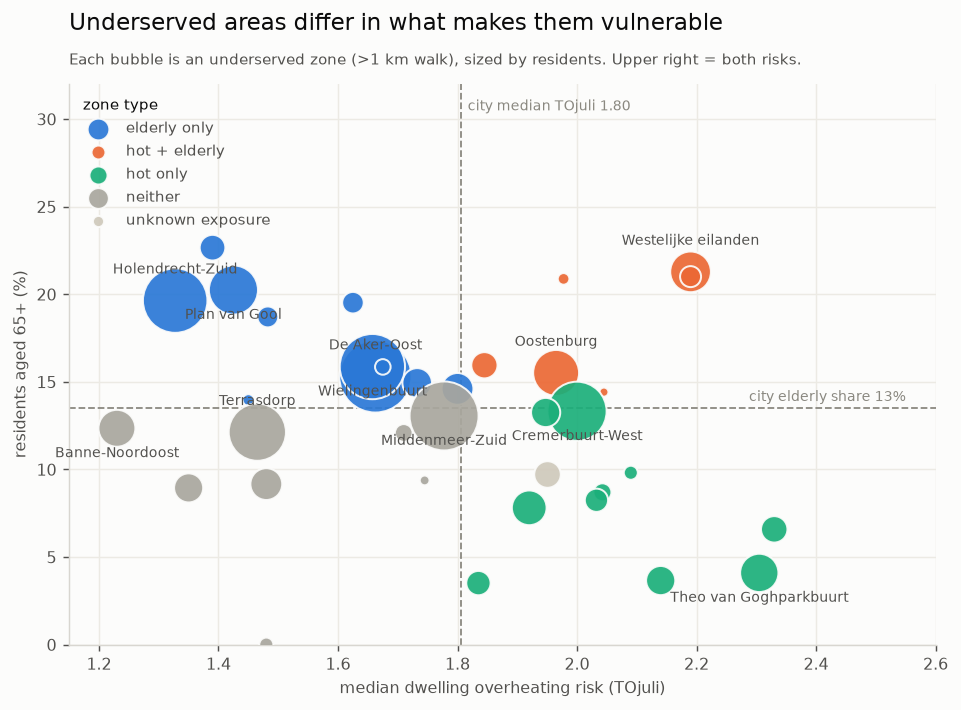

In [44]:
# The landscape of underserved zones on both need axes at once. A scatter rather than a
# ranked bar chart: the question is what kinds of need exist and how zones cluster, which a
# ranking flattens into a single order it cannot justify.
COLOURS = {"hot + elderly": ORANGE, "elderly only": BLUE, "hot only": AQUA,
           "neither": "#a9a79e", "unknown exposure": "#cfc9bb"}

fig, ax = plt.subplots(figsize=(8.6, 5.6))

ax.axvline(city_tojuli, color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.axhline(city_eld * 100, color=INK_3, linewidth=1, linestyle="--", zorder=1)
ax.annotate(f"city median TOjuli {city_tojuli:.2f}", (city_tojuli, 30.5), xytext=(4, 0),
            textcoords="offset points", fontsize=7.5, color=INK_3)
ax.annotate(f"city elderly share {city_eld:.0%}", (2.55, city_eld * 100), xytext=(0, 4),
            textcoords="offset points", fontsize=7.5, color=INK_3, ha="right")

plotted = zone_stats[zone_stats["tojuli"].notna()]
for t, grp in plotted.groupby("type"):
    ax.scatter(grp["tojuli"], grp["eld_share"] * 100,
               s=grp["residents"] / 22, c=COLOURS[t], label=t,
               edgecolor=SURFACE, linewidth=1.1, alpha=0.92, zorder=3)

# Label only the zones big enough to matter, and alternate above/below: neighbouring bubbles
# otherwise print their names on top of each other.
big = plotted[plotted["residents"] >= 9000].sort_values("tojuli")
for i, r in enumerate(big.itertuples()):
    dy = 15 if i % 2 else -16
    ax.annotate(r.buurten.split(",")[0], (r.tojuli, r.eld_share * 100), xytext=(0, dy),
                textcoords="offset points", ha="center", fontsize=7.5, color=INK_2, zorder=4)

ax.set_xlabel("median dwelling overheating risk (TOjuli)")
ax.set_ylabel("residents aged 65+ (%)")
ax.set_xlim(1.15, 2.6)
ax.set_ylim(0, 32)
ax.grid(color="#eceae4", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left", title="zone type",
          title_fontsize=8.5, alignment="left", markerscale=0.42)
ax.set_title("Underserved areas differ in what makes them vulnerable",
             fontsize=12.5, color=INK, loc="left", pad=30)
ax.text(0, 1.035, "Each bubble is an underserved zone (>1 km walk), sized by residents. "
        "Upper right = both risks.", transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig(FIGS / "zone_typology.png")
plt.show()


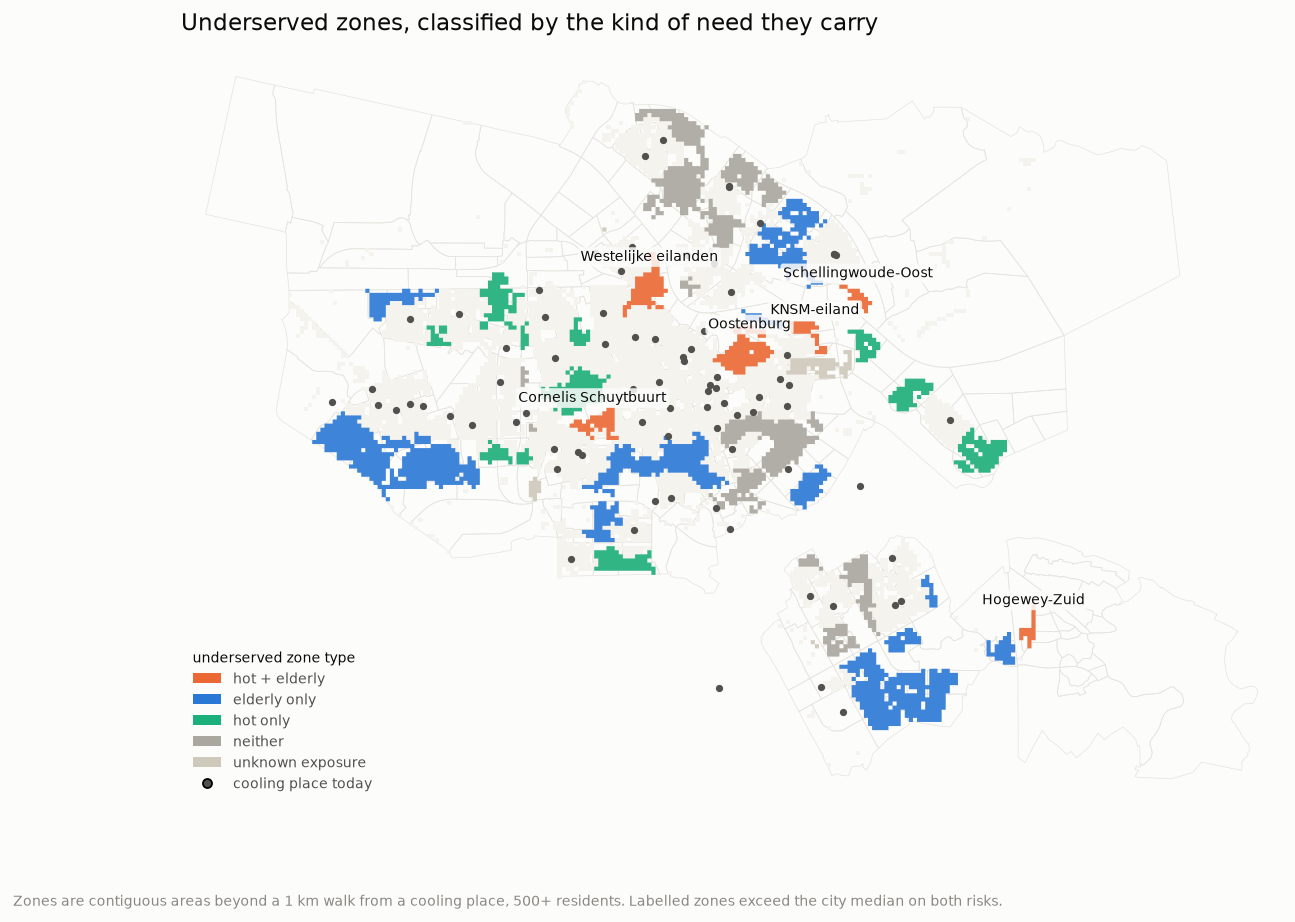

In [45]:
fig, ax = plt.subplots(figsize=(11, 11 * aspect))

b.boundary.plot(ax=ax, color="#e6e4de", linewidth=0.4, zorder=1)
squares.plot(ax=ax, color="#f5f3ee", zorder=2)          # city as a muted ground

for t, colour in COLOURS.items():
    sel = zone_stats[zone_stats["type"] == t]
    if len(sel):
        sel.plot(ax=ax, color=colour, edgecolor="none", alpha=0.9, zorder=3, label=t)

facilities.plot(ax=ax, color=INK_2, markersize=9, zorder=4)

for r in priority.itertuples():
    p = r.geometry.representative_point()
    ax.annotate(r.buurten.split(",")[0], (p.x, p.y), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=7.5, color=INK,
                zorder=5, bbox=dict(boxstyle="round,pad=0.2", facecolor=SURFACE,
                                    edgecolor="none", alpha=0.85))

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in COLOURS.values()] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=INK_2,
           markersize=5, label="cooling place today")]
ax.legend(handles, list(COLOURS) + ["cooling place today"], loc="lower left", frameon=False,
          fontsize=8, labelcolor=INK_2, title="underserved zone type", title_fontsize=8,
          alignment="left", borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_axis_off()
ax.set_aspect("equal")
ax.set_title("Underserved zones, classified by the kind of need they carry",
             fontsize=13, color=INK, loc="left", pad=12)
fig.text(0.01, 0.005, "Zones are contiguous areas beyond a 1 km walk from a cooling place, "
         "500+ residents. Labelled zones exceed the city median on both risks.",
         fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "zone_typology_map.png")
plt.show()


## 14. Where would a new cooling place do the most good?

Section 13 classified zones with hard filters, which has a real flaw: a zone at 12.9% elderly
counts for nothing and one at 13.6% counts fully. That cliff has no justification behind it,
and it discards underserved areas simply for being young.

So this section weights instead of filtering - but **weights the people, not the criteria**:

```
demand = residents x age_factor x heat_factor
  age_factor  = 1 + (RR - 1) x elderly_share      RR = heat-mortality risk ratio for 65+
  heat_factor = TOjuli / city median, clipped to [0.5, 2.0], neutral 1.0 where unmeasured
```

`heat_factor` is measured, not chosen - a square's overheating relative to the city's. `RR` is
a genuine assumption, so it is run at 1x (no age weighting), 2x, 3x and 5x rather than picked
once. Squares with no TOjuli get 1.0, so unmeasured areas are neither rewarded nor excluded.

The output is a **continuous effect surface**: for every point in Amsterdam, the unserved
weighted demand a new cooling place there would bring within 1 km. No sites are chosen and
nothing is filtered out - low-elderly underserved areas still appear, just less brightly.


In [46]:
from shapely.geometry import Point

SURFACE_F = PROCESSED / "effect_surface.gpkg"
STEP = 200

near["eld_share"] = (near[ELDERLY].fillna(0) / near[POP]).clip(0, 1)
near["heat_f"] = (near["tojuli"] / city_tojuli).clip(0.5, 2.0).fillna(1.0)

if SURFACE_F.exists():
    cand = gpd.read_file(SURFACE_F)
else:
    city = b.union_all()
    xs = np.arange(minx, maxx, STEP)
    ys = np.arange(miny, maxy, STEP)
    cand = gpd.GeoDataFrame(geometry=[Point(x, y) for x in xs for y in ys], crs=RD)
    cand = cand[cand.within(city)].reset_index(drop=True)

    c_nodes, c_snap = ox.distance.nearest_nodes(
        G, X=cand.geometry.x, Y=cand.geometry.y, return_dist=True)
    cand["node"], cand["snap"] = c_nodes, c_snap
    # A point 400 m from the nearest footpath is not a plausible site.
    cand = cand[cand["snap"] <= 200].reset_index(drop=True)

    unserved = (near["net_m"] > RADIUS).to_numpy()
    reach = []
    for node, snap in zip(cand["node"], cand["snap"]):
        dd = nx.single_source_dijkstra_path_length(G, node, cutoff=RADIUS, weight="length")
        arr = np.fromiter((dd.get(k, np.inf) for k in dem_nodes), float, len(dem_nodes))
        reach.append((arr + snap + dem_snap) <= RADIUS)
    R = np.array(reach)

    for RR in (1, 2, 3, 5):
        demand = (near[POP] * (1 + (RR - 1) * near["eld_share"]) * near["heat_f"]).to_numpy()
        cand[f"gain_rr{RR}"] = R[:, unserved] @ demand[unserved]
    cand.drop(columns=["node"]).to_file(SURFACE_F, driver="GPKG")

print(f"{len(cand):,} candidate points on a {STEP} m grid")


4,071 candidate points on a 200 m grid


### 14a. The weighting turns out not to matter

Before reading anything off the surface, check how much the `RR` assumption drives it.


In [47]:
cols = [f"gain_rr{r}" for r in (1, 2, 3, 5)]
print(cand[cols].corr(method="spearman").round(3).to_string())


          gain_rr1  gain_rr2  gain_rr3  gain_rr5
gain_rr1     1.000     1.000     0.999     0.997
gain_rr2     1.000     1.000     1.000     0.998
gain_rr3     0.999     1.000     1.000     0.999
gain_rr5     0.997     0.998     0.999     1.000


**Spearman correlations of 0.997 to 1.000.** Ranking locations by unweighted population and
by population weighted 5x toward the elderly gives essentially the same answer.

That resolves the argument rather than winning it. The worry about arbitrary weights was
real, and so was the objection that hard filters discard young underserved areas - but
empirically **neither choice changes where a new cooling place would help most.** Geography
dominates: how many people currently sit beyond a kilometre, and how many of them one new
location can reach. Elderly share and overheating vary far less across the city than
population density does.

This is worth more than either position we argued. A weighted composite would have looked
sophisticated and been indistinguishable from counting residents; a strict filter would have
excluded areas for no gain in discrimination. Testing it took four lines.

The surface below uses RR = 3. Any of the four would produce the same map.


In [48]:
# The highest-scoring points cluster together - the top ten sit in one gap in West, which is
# one opportunity, not ten. Thin greedily: take the best point, then only accept further ones
# more than MIN_SEP away, so each row is a distinct area.
MIN_SEP = 1200

ranked = cand.sort_values("gain_rr3", ascending=False)
picked = []
for r in ranked.itertuples():
    if all(r.geometry.distance(p.geometry) >= MIN_SEP for p in picked):
        picked.append(r)
    if len(picked) == 8:
        break

hotspots = gpd.GeoDataFrame(
    [{"gain": p.gain_rr3, "geometry": p.geometry} for p in picked], crs=RD)
hotspots = gpd.sjoin(hotspots, b[["buurt", "stadsdeel", "geometry"]],
                     predicate="within", how="left").drop(columns="index_right")
hotspots.index = range(1, len(hotspots) + 1)

print("distinct high-effect areas (unserved weighted residents reached from each):")
print(hotspots[["gain", "buurt", "stadsdeel"]].round(0).to_string())


distinct high-effect areas (unserved weighted residents reached from each):
      gain                   buurt   stadsdeel
1  27267.0              Lootsbuurt        West
2  23249.0         IJselbuurt-West        Zuid
3  15764.0       Linnaeusparkbuurt        Oost
4  14672.0        Belgiëplein e.o.  Nieuw-West
5  14419.0    Haarlemmerbuurt-West     Centrum
6  13263.0     Transvaalbuurt-West        Oost
7  12193.0  Theo van Goghparkbuurt        Oost
8  11865.0                  Gein 2    Zuidoost


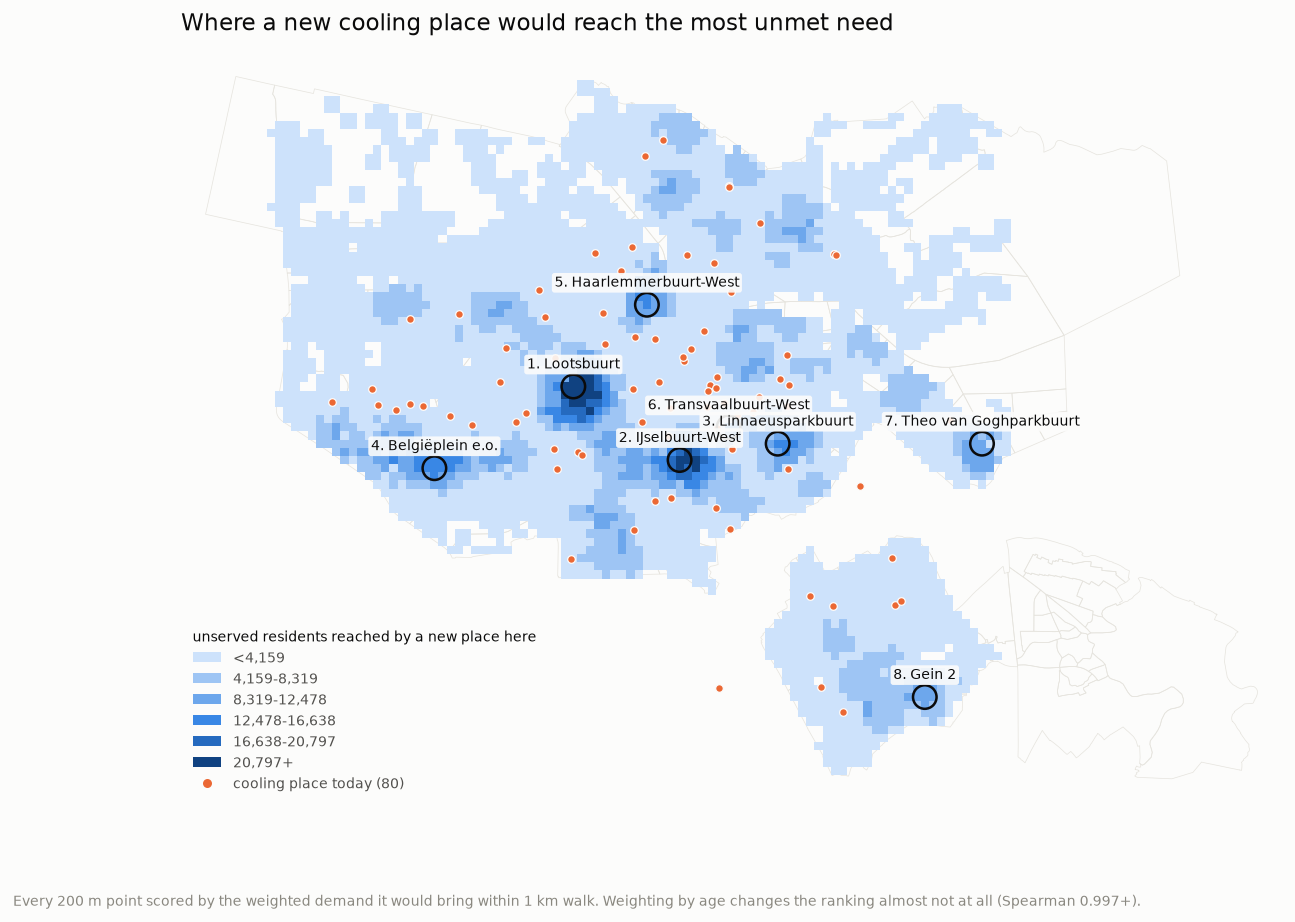

In [49]:
# Each candidate point stands for its 200 m cell, so draw them as squares: a scatter of dots
# would leave gaps that read as 'no data' rather than 'no effect'.
cells = cand.copy()
cells["geometry"] = cells.geometry.buffer(STEP / 2, cap_style=3)

vmax = cells["gain_rr3"].quantile(0.995)      # a few extreme points would flatten the ramp
bounds = [0, vmax * 0.2, vmax * 0.4, vmax * 0.6, vmax * 0.8, vmax, vmax * 10]
labels = [f"<{bounds[1]:,.0f}", f"{bounds[1]:,.0f}-{bounds[2]:,.0f}",
          f"{bounds[2]:,.0f}-{bounds[3]:,.0f}", f"{bounds[3]:,.0f}-{bounds[4]:,.0f}",
          f"{bounds[4]:,.0f}-{bounds[5]:,.0f}", f"{bounds[5]:,.0f}+"]

fig, ax = plt.subplots(figsize=(11, 11 * aspect))
b.boundary.plot(ax=ax, color="#e6e4de", linewidth=0.4, zorder=1)
cells.plot(ax=ax, column="gain_rr3", cmap=ListedColormap(RAMP),
           norm=BoundaryNorm(bounds, len(RAMP)), zorder=2)
facilities.plot(ax=ax, color=ORANGE, markersize=18, edgecolor=SURFACE, linewidth=0.7, zorder=3)
hotspots.plot(ax=ax, color="none", edgecolor=INK, linewidth=1.4, markersize=170, zorder=4)

# One label per distinct area, numbered to match the table above.
for rank, r in hotspots.iterrows():
    ax.annotate(f"{rank}. {r.buurt}", (r.geometry.x, r.geometry.y), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=7.5, color=INK, zorder=5,
                bbox=dict(boxstyle="round,pad=0.2", facecolor=SURFACE, edgecolor="none",
                          alpha=0.9))

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c) for c in RAMP] + [
    Line2D([], [], marker="o", linestyle="none", color="none", markerfacecolor=ORANGE,
           markeredgecolor=SURFACE, markersize=6, label=f"cooling place today ({len(facilities)})")]
ax.legend(handles, labels + [handles[-1].get_label()], loc="lower left", frameon=False,
          fontsize=8, labelcolor=INK_2, title="unserved residents reached by a new place here",
          title_fontsize=8, alignment="left", borderaxespad=0.4, labelspacing=0.45)

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_axis_off()
ax.set_aspect("equal")
ax.set_title("Where a new cooling place would reach the most unmet need",
             fontsize=13, color=INK, loc="left", pad=12)
fig.text(0.01, 0.005, "Every 200 m point scored by the weighted demand it would bring within "
         "1 km walk. Weighting by age changes the ranking almost not at all (Spearman 0.997+).",
         fontsize=7.5, color=INK_3)
fig.savefig(FIGS / "effect_surface.png")
plt.show()
